## Analysis contexts

**Common cohort (N=110) provides the matched basis for cross-modality predictive comparison.** Full availability (N=139) preserves the modality-specific results. The two contexts are compared section by section. Model families are selected by mean inner-CV macro-F1, not outer-test performance. Differences cannot be attributed solely to sample size because preprocessing and search spaces also differ.

Training is disabled by default; reporting cells load the saved common-cohort results.

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

from pathlib import Path as P110Path
import sys as p110_sys
import pandas as p110_pd
from IPython.display import display, Image as P110Image, Markdown as P110Markdown
p110_repo = next(p for p in [P110Path.cwd(), *P110Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(p110_repo) not in p110_sys.path:
    p110_sys.path.insert(0, str(p110_repo))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110, _primary110_reporting_CONFIG as P110_CONFIG
p110_root = P110Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
p110_bundle = load_primary110(p110_root)

p110_config = 'transcriptomics'
p110_output = p110_root / 'primary_110' / p110_config
p110_context = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_context_comparison.csv')
p110_context['analysis_context'] = ['Full availability (N=139)', 'Common cohort (N=110)']
p110_secondary_label, p110_primary_label = 'Full availability (N=139)', 'Common cohort (N=110)'
p110_folder, p110_prefix, p110_secondary_family, *_ = P110_CONFIG[p110_config]
p110_primary_family = p110_context.iloc[1].selected_family

from scripts.OligoPolyThesis.utils_ml_oligopoly import quiet_candidate_f_tests
from scripts.OligoPolyThesis.utils_ml_oligopoly import display_interpretation


# Transcriptomics Representation Learning and Modelling

This notebook evaluates transcriptomics representations for downstream oligometastatic versus polymetastatic classification.

It starts from the preprocessed transcriptomics matrix created in the preprocessing notebook:

- samples as rows;
- log2(TPM + 1) transcriptomics features as columns;
- `Polymetastatic = 0` for oligometastatic patients;
- `Polymetastatic = 1` for polymetastatic patients.

The aim is to benchmark several representations under the same supervised modelling protocol:

1. gene-level expression baseline;
2. PCA components as a linear dimensionality-reduction baseline;
3. GenomicSuperSignature RAV scores;
4. MultiPLIER latent-variable scores;
5. Tybalt VAE latent representations.

For each representation, three candidate classifiers (L1-regularised logistic regression, Random Forest, and XGBoost) are evaluated under the same nested cross-validation framework, so representations and classifiers can both be compared fairly.

The notebook proceeds from cohort definition and the direct gene-level baseline to fold-local PCA and externally pretrained representations. Descriptive geometry is kept separate from predictive comparison, held-out evaluation and interpretation. Tybalt Integrated Gradients is a supplementary analysis; it does not replace the selected predictive model.


## Scope and limitations

Cohort-dependent preprocessing in external input generation cannot be ruled out. Full-data exploratory projections are descriptive only.


In [ ]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess

from sklearn.model_selection import StratifiedKFold
import warnings
from IPython.display import Markdown


In [ ]:
ROOT = Path.cwd()

while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

thesis_print("Project root:")
thesis_print(ROOT)

from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    fit_full_data_pca_exploratory,
    split_transcriptomics_features_target_metadata,
    summarise_representation_results,
    build_representation_classifiers,
    wrap_with_pca,
    wrap_with_feature_selection,
    wrap_with_tybalt,
    TybaltEncoderTransformer,
    plot_metric_boxplots,
    plot_train_test_gap_boxplots,
    plot_exploratory_pca_variance_and_scatter,
    plot_calibration_curve,
    compute_representation_silhouette,
    plot_umap_representation,
    plot_roc_curves,
    plot_precision_recall_curves,
    plot_confusion_matrix,
    build_gene_level_tpm_classifiers, tpm_outer_splits, evaluate_tpm_representation,
    validate_tpm_oof, tpm_pooled_oof_metrics, rank_tpm_inner_scores,
    summarise_tpm_gene_stability,
    tpm_flaml_settings, run_nested_cv_with_flaml_tpm,
)
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    extract_sampler_from_best_params,
    select_mean_inner_combination,
    plot_thesis_saved_figure,
    load_tybalt_ig_results,
)

Project root:
/home/martapimentel/proj-mcpp-breast


## 1. Data and cohort definition

### Input and output paths

We define the path to the preprocessed transcriptomics matrix and the output directory for representation-learning and modelling results.

In [3]:
transcriptomics_preprocessed_dir = (
    "/mnt/data3/MCPP-Breast/Transcriptomic-Data/Preprocessed"
)

preprocessed_transcriptomics_path = os.path.join(
    transcriptomics_preprocessed_dir,
    "transcriptomics_oligo_poly_log2_tpm_preprocessed.csv"
)

feature_mapping_path = os.path.join(
    transcriptomics_preprocessed_dir,
    "transcriptomics_feature_name_mapping.csv"
)

output_dir = (
    "/mnt/data3/MCPP-Breast/"
    "Machine-Learning-Models-poly_vs_oligo/"
    "Transcriptomics-Representation-Learning"
)

os.makedirs(output_dir, exist_ok=True)

thesis_print("Preprocessed transcriptomics path:")
thesis_print(preprocessed_transcriptomics_path)

thesis_print("\nFeature mapping path:")
thesis_print(feature_mapping_path)

thesis_print("\nOutput directory:")
thesis_print(output_dir)

Preprocessed transcriptomics path:
/mnt/data3/MCPP-Breast/Transcriptomic-Data/Preprocessed/transcriptomics_oligo_poly_log2_tpm_preprocessed.csv

Feature mapping path:
/mnt/data3/MCPP-Breast/Transcriptomic-Data/Preprocessed/transcriptomics_feature_name_mapping.csv

Output directory:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning


## Load Preprocessed Transcriptomics Data

We load the final preprocessed transcriptomics matrix generated in the preprocessing notebook.

In [4]:
transcriptomics_df = pd.read_csv(preprocessed_transcriptomics_path)

thesis_print("Transcriptomics dataframe shape:")
thesis_print(transcriptomics_df.shape)

thesis_print("\nFirst columns:")
thesis_print(transcriptomics_df.columns[:10].tolist())

thesis_display(transcriptomics_df.head())

Transcriptomics dataframe shape:
(139, 18265)

First columns:
['sample_id_original', 'sample_id_normalised', 'transcriptomics_source', 'metastatic_group', 'Polymetastatic', 'transcriptomics__ENSG00000000003', 'transcriptomics__ENSG00000000005', 'transcriptomics__ENSG00000000419', 'transcriptomics__ENSG00000000457', 'transcriptomics__ENSG00000000460']


,sample_id_original,sample_id_normalised,transcriptomics_source,metastatic_group,Polymetastatic,transcriptomics__ENSG00000000003,transcriptomics__ENSG00000000005,transcriptomics__ENSG00000000419,transcriptomics__ENSG00000000457,transcriptomics__ENSG00000000460,...,transcriptomics__ENSG00000289721,transcriptomics__ENSG00000289746,transcriptomics__ENSG00000289762,transcriptomics__ENSG00000290292,transcriptomics__ENSG00000291237,transcriptomics__ENSG00000291307,transcriptomics__ENSG00000291309,transcriptomics__ENSG00000291316,transcriptomics__ENSG00000291317,transcriptomics__ENSG00000293543
0,101B.WTS_S57,101B,rnaseq_tpm_norm.txt,oligometastatic,0,3.575,0.000,7.108,5.442,5.503,...,0.000,0.000,0.000,3.874,9.325,0.000,6.060,5.032,4.841,0.000
1,108B.WTS_S64,108B,rnaseq_tpm_norm.txt,oligometastatic,0,4.447,0.000,6.674,3.731,4.848,...,0.977,2.580,4.518,4.208,6.840,0.000,5.751,1.311,4.119,0.000
2,10B.WTS_S24,10B,rnaseq_tpm_norm.txt,oligometastatic,0,4.698,0.000,5.981,4.556,5.729,...,2.668,1.598,0.000,5.191,7.456,0.000,5.609,0.000,5.453,0.000
3,110B.WTS_S66,110B,rnaseq_tpm_norm.txt,oligometastatic,0,4.242,0.000,7.116,3.620,4.495,...,0.000,3.426,0.000,4.180,8.730,0.000,5.954,0.000,3.619,0.000
4,115B.WTS_S2,115B,rnaseq_tpm_norm.txt,oligometastatic,0,3.436,3.174,6.883,4.456,5.580,...,3.117,4.866,0.000,4.905,7.681,0.000,5.292,3.756,3.962,0.000


## Define Features, Target and Metadata

Only columns starting with `transcriptomics__` are used as model features.

Metadata columns such as `sample_id_original`, `sample_id_normalised`, `transcriptomics_source`, and `metastatic_group` are retained for sample traceability but excluded from the model feature matrix `X`.

In [5]:
target_col = "Polymetastatic"

X, y, metadata_df, feature_cols, metadata_cols = (
    split_transcriptomics_features_target_metadata(
        transcriptomics_df=transcriptomics_df,
        target_col=target_col,
        feature_prefix="transcriptomics__"
    )
)

thesis_print("X shape:")
thesis_print(X.shape)

thesis_print("\ny shape:")
thesis_print(y.shape)

thesis_print("\nTarget distribution:")
thesis_display(y.value_counts())

thesis_print("\nMetadata columns excluded from X:")
thesis_print(metadata_cols)

thesis_print("\nFeature dtype counts:")
thesis_display(X.dtypes.value_counts())

thesis_print("\nSanity check passed.")

X shape:
(139, 18260)

y shape:
(139,)

Target distribution:


Polymetastatic
1    85
0    54
Name: count, dtype: int64


Metadata columns excluded from X:
['sample_id_original', 'sample_id_normalised', 'transcriptomics_source', 'metastatic_group', 'Polymetastatic']

Feature dtype counts:


float64    18260
Name: count, dtype: int64


Sanity check passed.


## Load Feature Mapping

The mapping links transcriptomic feature names to Ensembl gene IDs and gene symbols for interpretation.

In [6]:
if os.path.exists(feature_mapping_path):
    feature_mapping_df = pd.read_csv(feature_mapping_path)

    thesis_print("Feature mapping shape:")
    thesis_print(feature_mapping_df.shape)

    thesis_display(feature_mapping_df.head())

else:
    feature_mapping_df = pd.DataFrame()
    thesis_print("Feature mapping file not found.")

Feature mapping shape:
(18260, 3)


,model_feature_name,ensembl_gene_id,gene_name
0,transcriptomics__ENSG00000000003,ENSG00000000003,TSPAN6
1,transcriptomics__ENSG00000000005,ENSG00000000005,TNMD
2,transcriptomics__ENSG00000000419,ENSG00000000419,DPM1
3,transcriptomics__ENSG00000000457,ENSG00000000457,SCYL3
4,transcriptomics__ENSG00000000460,ENSG00000000460,FIRRM


### Cohort comparison

Full availability retains the patients available to the modality. The common-cohort comparison uses identical patient membership and frozen outer-fold assignments across all seven inputs.

In [2]:
thesis_display(p110_pd.DataFrame([
    {'Context': p110_secondary_label, 'N': 139, 'Oligometastatic': 54, 'Polymetastatic': 85},
    {'Context': p110_primary_label, 'N': 110, 'Oligometastatic': 43, 'Polymetastatic': 67},
]))
thesis_display(p110_pd.crosstab(p110_bundle['cohort'].outer_fold, p110_bundle['cohort'].y_true).rename(columns={0:'Oligometastatic',1:'Polymetastatic'}))

,Context,N,Oligometastatic,Polymetastatic
0,Full availability (N=139),139,54,85
1,Common cohort (N=110),110,43,67


y_true,Oligometastatic,Polymetastatic
outer_fold,,
1,8,14
2,8,14
3,9,13
4,9,13
5,9,13


## Define Cross-Validation Strategy

We use nested cross-validation:

- the inner CV loop is used for hyperparameter tuning and representation hyperparameter selection;
- the outer CV loop is used only for performance estimation.

This keeps model selection separate from performance estimation.

All 21 representation–classifier combinations reuse the same five frozen outer partitions. Patient identifiers, ordering and labels must agree across representations. Manual tuning uses five stratified inner folds and macro-F1.


In [7]:
RANDOM_STATE = 42

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = "f1_macro"

# One frozen outer partition, reused by all 21 combinations and FLAML.
outer_splits = tpm_outer_splits(outer_cv, X, y)
RUN_NESTED_CV = False
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
FLAML_TIME_BUDGET_SECONDS = 120 
RUN_EXPLORATORY = False  # Optional full-data PCA/Tybalt/silhouette/UMAP recomputation.
tpm_registry = {}
if RUN_FLAML or RUN_FULL_COHORT_FLAML:
    tpm_flaml_settings(FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)



## 2. Predictive representations

The transcriptomics analysis compares alternative representations of gene expression under the same nested cross-validation framework.

Five representation strategies are evaluated:

1. gene-level expression without dimensionality reduction;
2. PCA-based representations;
3. GenomicSuperSignature;
4. MultiPLIER;
5. Tybalt pre-trained VAE representations.

For each representation, the same candidate classifier families are evaluated: L1-regularized logistic regression, Random Forest, and XGBoost.

Class imbalance is handled as part of the modelling pipeline rather than through a fixed preprocessing decision. For each classifier, the inner cross-validation procedure selects between no resampling and SMOTE. Because resampling is performed inside the pipeline, synthetic samples are generated exclusively from the training portion of each cross-validation fold.

Features are standardized before modelling. This is required for regularized logistic regression and also ensures that distance-based SMOTE operates in a standardized feature space. For PCA-based models, the pipeline order is:

**standardization → PCA → resampling → classifier**

so that both PCA and SMOTE are fitted exclusively using training-fold data.

Model and representation selection is based on mean inner-cross-validation macro-F1 across outer folds. Outer-fold test metrics are reserved exclusively for estimating generalisation performance and are not used to select the preferred representation-classifier combination.

### 2.1 Direct gene-level expression baseline

This baseline uses the filtered log2(TPM + 1) gene expression features directly.

Because the feature space is high-dimensional, we evaluate three candidate classifiers (L1-regularised logistic regression, Random Forest, and XGBoost) under nested cross-validation.

Gene-level selection is mandatory inside the pipeline: the existing F-test k=200, mutual-information k=200 and F-test k=500 candidates are retained, with no selector passthrough. Scaling, selection and any SMOTE are fitted using training data within CV. Other representations retain their existing selector grids.

Some candidate F-test selectors encountered zero within-class variance in individual training partitions. scikit-learn gives undefined F-scores the lowest selection priority; those scores are not passed to the classifier. Repeated warnings are suppressed for readability.


In [8]:
with quiet_candidate_f_tests():
    gene_level_classifiers = build_gene_level_tpm_classifiers(RANDOM_STATE, X.shape[1])
    gene_level_results_dfs, gene_level_predictions_dfs = evaluate_tpm_representation(
        X=X, y=y, representation_base_name="gene_level", metadata_df=metadata_df,
        outer_cv=outer_splits, inner_cv=inner_cv, scoring=scoring, output_dir=output_dir,
        classifiers=gene_level_classifiers, registry=tpm_registry, reference_metadata=metadata_df,
        reference_y=y, run_nested_cv=RUN_NESTED_CV,
    )



gene_level_logreg_l1 | Outer fold 1


Best inner score:
0.575

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.357, 'balanced_accuracy': 0.310, 'f1': 0.5, 'f1_macro': 0.3, 'precision_poly': 0.474, 'sensitivity_poly': 0.529, 'recall_oligo': 0.091, 'roc_auc': 0.364, 'specificity_oligo': np.float64(0.091)}

gene_level_logreg_l1 | Outer fold 2


Best inner score:
0.560

Best params:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.5, 'balanced_accuracy': 0.492, 'f1': 0.562, 'f1_macro': 0.490, 'precision_poly': 0.6, 'sensitivity_poly': 0.529, 'recall_oligo': 0.455, 'roc_auc': 0.433, 'specificity_oligo': np.float64(0.455)}

gene_level_logreg_l1 | Outer fold 3


Best inner score:
0.587

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.430, 'f1': 0.571, 'f1_macro': 0.429, 'precision_poly': 0.556, 'sensitivity_poly': 0.588, 'recall_oligo': 0.273, 'roc_auc': 0.380, 'specificity_oligo': np.float64(0.273)}

gene_level_logreg_l1 | Outer fold 4


Best inner score:
0.554

Best params:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.429, 'balanced_accuracy': 0.401, 'f1': 0.529, 'f1_macro': 0.401, 'precision_poly': 0.529, 'sensitivity_poly': 0.529, 'recall_oligo': 0.273, 'roc_auc': 0.439, 'specificity_oligo': np.float64(0.273)}

gene_level_logreg_l1 | Outer fold 5


...

Best inner score:
0.660

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.643, 'balanced_accuracy': 0.658, 'f1': 0.667, 'f1_macro': 0.641, 'precision_poly': 0.769, 'sensitivity_poly': 0.588, 'recall_oligo': 0.727, 'roc_auc': 0.749, 'specificity_oligo': np.float64(0.727)}

gene_level_xgboost | Outer fold 2


Best inner score:
0.709

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.643, 'balanced_accuracy': 0.610, 'f1': 0.722, 'f1_macro': 0.611, 'precision_poly': 0.684, 'sensitivity_poly': 0.765, 'recall_oligo': 0.455, 'roc_auc': 0.620, 'specificity_oligo': np.float64(0.455)}

gene_level_xgboost | Outer fold 3


Best inner score:
0.732

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.429, 'balanced_accuracy': 0.385, 'f1': 0.556, 'f1_macro': 0.378, 'precision_poly': 0.526, 'sensitivity_poly': 0.588, 'recall_oligo': 0.182, 'roc_auc': 0.476, 'specificity_oligo': np.float64(0.182)}

gene_level_xgboost | Outer fold 4


Best inner score:
0.666

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.643, 'balanced_accuracy': 0.642, 'f1': 0.688, 'f1_macro': 0.635, 'precision_poly': 0.733, 'sensitivity_poly': 0.647, 'recall_oligo': 0.636, 'roc_auc': 0.743, 'specificity_oligo': np.float64(0.636)}

gene_level_xgboost | Outer fold 5


Best inner score:
0.715

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': SelectKBest(k=200, score_func=<function mutual_info_classif at 0x780a63f74ea0>)}

Test metrics:
{'accuracy': 0.519, 'balanced_accuracy': 0.494, 'f1': 0.606, 'f1_macro': 0.494, 'precision_poly': 0.625, 'sensitivity_poly': 0.588, 'recall_oligo': 0.4, 'roc_auc': 0.541, 'specificity_oligo': np.float64(0.4)}


### 2.2 Institutional fold-local PCA

PCA on the institutional oligo/poly dataset is already part of the predictive analysis. In cell 23, `wrap_with_pca` places `StandardScaler` and PCA inside the classifier pipeline. Each inner-training partition fits its own scaler and PCA; after tuning, the selected pipeline is refitted on the outer-training patients and applied to the held-out outer fold. The candidate component counts are 5, 10, 20 and 50.

This is distinct from transferring externally pretrained GenomicSuperSignature, MultiPLIER or Tybalt representations. The separate 20-component full-cohort PCA below is used only for exploratory visualisation and silhouette analysis; it is not the PCA input used to estimate predictive performance.


In [9]:
pca_classifiers = wrap_with_pca(
    build_representation_classifiers(random_state=RANDOM_STATE, n_features=X.shape[1], use_feature_selection=False),
    n_components_grid=[5, 10, 20, 50], random_state=RANDOM_STATE,
)
pca_results_dfs, pca_predictions_dfs = evaluate_tpm_representation(
    X=X, y=y, representation_base_name="pca", metadata_df=metadata_df,
    outer_cv=outer_splits, inner_cv=inner_cv, scoring=scoring, output_dir=output_dir,
    classifiers=pca_classifiers, registry=tpm_registry, reference_metadata=metadata_df,
    reference_y=y, run_nested_cv=RUN_NESTED_CV,
)



pca_logreg_l1 | Outer fold 1


Best inner score:
0.497

Best params:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'pca__n_components': 10, 'sampler': 'passthrough'}

Test metrics:
{'accuracy': 0.536, 'balanced_accuracy': 0.586, 'f1': 0.48, 'f1_macro': 0.530, 'precision_poly': 0.75, 'sensitivity_poly': 0.353, 'recall_oligo': 0.818, 'roc_auc': 0.455, 'specificity_oligo': np.float64(0.818)}

pca_logreg_l1 | Outer fold 2


Best inner score:
0.476

Best params:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'pca__n_components': 20, 'sampler': 'passthrough'}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.583, 'f1': 0.6, 'f1_macro': 0.569, 'precision_poly': 0.692, 'sensitivity_poly': 0.529, 'recall_oligo': 0.636, 'roc_auc': 0.631, 'specificity_oligo': np.float64(0.636)}

pca_logreg_l1 | Outer fold 3


Best inner score:
0.530

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'pca__n_components': 10, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.357, 'balanced_accuracy': 0.310, 'f1': 0.5, 'f1_macro': 0.3, 'precision_poly': 0.474, 'sensitivity_poly': 0.529, 'recall_oligo': 0.091, 'roc_auc': 0.369, 'specificity_oligo': np.float64(0.091)}

pca_logreg_l1 | Outer fold 4


Best inner score:
0.507

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'pca__n_components': 50, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.479, 'f1': 0.483, 'f1_macro': 0.464, 'precision_poly': 0.583, 'sensitivity_poly': 0.412, 'recall_oligo': 0.545, 'roc_auc': 0.417, 'specificity_oligo': np.float64(0.545)}

pca_logreg_l1 | Outer fold 5


...

Best inner score:
0.559

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'pca__n_components': 10, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.615, 'f1': 0.538, 'f1_macro': 0.569, 'precision_poly': 0.778, 'sensitivity_poly': 0.412, 'recall_oligo': 0.818, 'roc_auc': 0.652, 'specificity_oligo': np.float64(0.818)}

pca_xgboost | Outer fold 2


Best inner score:
0.553

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.6, 'pca__n_components': 50, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.5, 'balanced_accuracy': 0.588, 'f1': 0.3, 'f1_macro': 0.456, 'precision_poly': 1.0, 'sensitivity_poly': 0.176, 'recall_oligo': 1.0, 'roc_auc': 0.513, 'specificity_oligo': np.float64(1.0)}

pca_xgboost | Outer fold 3


Best inner score:
0.572

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'pca__n_components': 50, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.357, 'balanced_accuracy': 0.390, 'f1': 0.308, 'f1_macro': 0.354, 'precision_poly': 0.444, 'sensitivity_poly': 0.235, 'recall_oligo': 0.545, 'roc_auc': 0.332, 'specificity_oligo': np.float64(0.545)}

pca_xgboost | Outer fold 4


Best inner score:
0.561

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'pca__n_components': 50, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.536, 'balanced_accuracy': 0.537, 'f1': 0.581, 'f1_macro': 0.530, 'precision_poly': 0.643, 'sensitivity_poly': 0.529, 'recall_oligo': 0.545, 'roc_auc': 0.497, 'specificity_oligo': np.float64(0.545)}

pca_xgboost | Outer fold 5


Best inner score:
0.546

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'pca__n_components': 20, 'sampler': SMOTE(random_state=42)}

Test metrics:
{'accuracy': 0.370, 'balanced_accuracy': 0.376, 'f1': 0.414, 'f1_macro': 0.367, 'precision_poly': 0.5, 'sensitivity_poly': 0.353, 'recall_oligo': 0.4, 'roc_auc': 0.424, 'specificity_oligo': np.float64(0.4)}


#### Full-cohort PCA for descriptive visualisation only

This PCA representation is fitted on the full dataset only for visualisation and exploratory plots.

It should not be used to estimate supervised model performance.

In [10]:
if RUN_EXPLORATORY:
    pca_scores_path = os.path.join(
        output_dir,
        "transcriptomics_full_data_pca_scores_exploratory.csv"
    )

    pca_scores_df = fit_full_data_pca_exploratory(
        X=X,
        metadata_df=metadata_df,
        n_components=20,
        random_state=RANDOM_STATE,
        output_path=pca_scores_path
    )

    thesis_print("Exploratory PCA scores shape:")
    thesis_print(pca_scores_df.shape)

    thesis_print("\nSaved:")
    thesis_print(pca_scores_path)

    thesis_display(pca_scores_df.head())
else:
    thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")


Exploratory computation disabled; preserved notebook output predates this revision.


In [11]:
if RUN_EXPLORATORY:
    pca_explained_variance_path = os.path.join(
        output_dir,
        "transcriptomics_full_data_pca_explained_variance_exploratory.csv",
    )

    explained_variance_df, pca_plot_df = (
        plot_exploratory_pca_variance_and_scatter(
            X=X,
            y=y,
            n_components=20,
            random_state=RANDOM_STATE,
            output_path=pca_explained_variance_path,
        )
    )
else:
    thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")


Exploratory computation disabled; preserved notebook output predates this revision.


#### Preparation of externally pretrained representations

Some transcriptomic representations require software environments outside the main Python modelling pipeline, including R/Bioconductor packages or pretrained TensorFlow/Keras models.

The corresponding representation-generation scripts produce sample-level feature matrices that are subsequently loaded into this notebook for downstream nested cross-validation modelling.

The external scripts used are:

- `scripts/OligoPolyThesis/run_genomic_super_signature.R`: computes GenomicSuperSignature RAV scores and validation diagnostics;
- `scripts/OligoPolyThesis/run_multiplier.R`: projects the institutional cohort into the pretrained recount2 MultiPLIER latent-variable space;
- `scripts/OligoPolyThesis/run_tybalt.py`: prepares and applies pretrained Tybalt encoders.

The pretrained representation models themselves are learned from external public datasets and are not fitted using the oligometastatic/polymetastatic target labels. Any supervised feature selection, resampling, classifier fitting, and hyperparameter selection used for prediction are performed within the nested cross-validation framework described below.

In [12]:
external_representation_commands = {
    "GenomicSuperSignature": (
        "Rscript scripts/OligoPolyThesis/run_genomic_super_signature.R "
        "/mnt/data3/MCPP-Breast"
    ),
    "MultiPLIER": (
        "Rscript scripts/OligoPolyThesis/run_multiplier.R "
        "/mnt/data3/MCPP-Breast"
    ),
    "Tybalt": (
        "python scripts/OligoPolyThesis/run_tybalt.py "
        "/mnt/data3/MCPP-Breast"
    ),
}

thesis_print("Representation-generation commands:\n")

for representation_name, command in external_representation_commands.items():
    thesis_print(f"{representation_name}:")
    thesis_print(command)
    thesis_print()

Representation-generation commands:

GenomicSuperSignature:
Rscript scripts/OligoPolyThesis/run_genomic_super_signature.R /mnt/data3/MCPP-Breast

MultiPLIER:
Rscript scripts/OligoPolyThesis/run_multiplier.R /mnt/data3/MCPP-Breast

Tybalt:
python scripts/OligoPolyThesis/run_tybalt.py /mnt/data3/MCPP-Breast



### 2.3 GenomicSuperSignature

GenomicSuperSignature provides a transferable transcriptomic representation based on Replicable Axes of Variation (RAVs) learned from large public gene-expression collections.

Two outputs of GenomicSuperSignature are used for different purposes in this analysis.

First, `validate()` is applied to the complete institutional transcriptomics dataset as an exploratory quality-control analysis. The resulting validation scores quantify how strongly the principal components of the institutional expression dataset align with individual RAVs. These validation results are reported descriptively and are not used to select predictive features.

Second, sample-level scores are computed for all available RAVs using the pretrained RAVmodel. Predictive feature selection is then performed inside the nested cross-validation pipeline using SelectKBest, with the number of retained RAV features selected from 5, 10, 20, and 50 exclusively within the inner cross-validation loop.

This separation prevents the full institutional cohort from being used to choose the RAV features evaluated in held-out outer folds.

#### Load GenomicSuperSignature scores

We load sample-level scores for all available RAVs generated using the pretrained GenomicSuperSignature model.

No RAVs are selected based on the full institutional cohort for predictive modelling. Instead, supervised feature selection is performed later within the inner cross-validation loop.

Each column starting with `gss__` represents one GenomicSuperSignature-derived feature.

In [13]:
gss_output_dir = os.path.join(
    output_dir,
    "GenomicSuperSignature"
)

gss_scores_all_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_scores_all.csv"
)

gss_validation_results_csv_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_validation_results.csv"
)

gss_validation_results_txt_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_validation_results.txt"
)

gss_validation_results_rds_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_validation_results.rds"
)

gss_validated_ravs_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_validated_ravs_top.csv"
)

gss_gene_overlap_summary_path = os.path.join(
    gss_output_dir,
    "transcriptomics_gss_gene_overlap_summary.csv"
)

gss_run_summary_path = os.path.join(
    gss_output_dir,
    "transcriptomics_genomic_super_signature_run_summary.csv"
)

thesis_print("GSS output directory:")
thesis_print(gss_output_dir)

thesis_print("\nAll GSS scores path:")
thesis_print(gss_scores_all_path)

thesis_print("\nFile checks:")

for path in [
    gss_scores_all_path,
    gss_validation_results_csv_path,
    gss_validation_results_txt_path,
    gss_validation_results_rds_path,
    gss_validated_ravs_path,
    gss_gene_overlap_summary_path,
    gss_run_summary_path,
]:
    thesis_print(os.path.basename(path), "exists:", os.path.exists(path))

if not os.path.exists(gss_scores_all_path):
    raise FileNotFoundError(
        f"Could not find all GSS scores: {gss_scores_all_path}"
    )

if not os.path.exists(gss_validation_results_csv_path):
    raise FileNotFoundError(
        f"Could not find GSS validation results CSV: "
        f"{gss_validation_results_csv_path}"
    )

gss_scores_df = pd.read_csv(gss_scores_all_path)
gss_validation_df = pd.read_csv(gss_validation_results_csv_path)

thesis_print("\nGSS all scores shape:")
thesis_print(gss_scores_df.shape)

thesis_display(gss_scores_df.head())

thesis_print("\nGSS validation results:")
thesis_display(
    gss_validation_df
    .sort_values("score", ascending=False)
    .head(20)
)

if os.path.exists(gss_gene_overlap_summary_path):
    gss_gene_overlap_summary_df = pd.read_csv(
        gss_gene_overlap_summary_path
    )

    thesis_print("\nGSS gene overlap summary:")
    thesis_display(gss_gene_overlap_summary_df)

if os.path.exists(gss_validated_ravs_path):
    gss_validated_ravs_df = pd.read_csv(
        gss_validated_ravs_path
    )

    thesis_print("\nTop validated RAVs:")
    thesis_display(gss_validated_ravs_df.head(20))

if os.path.exists(gss_run_summary_path):
    gss_run_summary_df = pd.read_csv(
        gss_run_summary_path
    )

    thesis_print("\nGSS run summary:")
    thesis_display(gss_run_summary_df)

GSS output directory:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/GenomicSuperSignature

All GSS scores path:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/GenomicSuperSignature/transcriptomics_genomic_super_signature_scores_all.csv

File checks:
transcriptomics_genomic_super_signature_scores_all.csv exists: True
transcriptomics_genomic_super_signature_validation_results.csv exists: True
transcriptomics_genomic_super_signature_validation_results.txt exists: True
transcriptomics_genomic_super_signature_validation_results.rds exists: True
transcriptomics_genomic_super_signature_validated_ravs_top.csv exists: True
transcriptomics_gss_gene_overlap_summary.csv exists: True
transcriptomics_genomic_super_signature_run_summary.csv exists: True



GSS all scores shape:
(139, 4765)


,sample_id_normalised,gss__RAV1,gss__RAV2,gss__RAV3,gss__RAV4,gss__RAV5,gss__RAV6,gss__RAV7,gss__RAV8,gss__RAV9,...,gss__RAV4755,gss__RAV4756,gss__RAV4757,gss__RAV4758,gss__RAV4759,gss__RAV4760,gss__RAV4761,gss__RAV4762,gss__RAV4763,gss__RAV4764
0,101B,57.707,-48.145,14.073,-5.574,-1.654,-6.806,-4.628,12.500,21.835,...,-0.309,-0.881,-0.707,0.325,0.043,-0.443,-0.151,0.421,0.276,1.401
1,108B,56.813,-35.735,15.366,-1.384,-11.155,-10.877,3.291,9.919,13.578,...,-0.777,-0.879,-0.193,-0.529,-0.406,-0.348,1.613,-0.721,-0.194,-0.550
2,10B,77.456,-39.178,15.880,4.463,-8.110,-10.395,-5.836,6.216,9.606,...,0.623,-1.604,-1.295,0.647,0.353,2.677,0.524,-0.316,-1.713,1.004
3,110B,60.374,-19.819,-4.930,-12.328,-6.422,-4.272,-0.729,2.379,11.220,...,1.426,-2.471,0.454,1.320,-0.063,2.406,2.394,-3.073,-0.778,-2.890
4,115B,81.835,-41.727,7.904,-10.548,-4.957,-4.807,-4.341,14.635,21.901,...,0.183,-0.619,-1.304,0.473,0.152,2.921,1.066,-0.167,-2.507,-1.373



GSS validation results:


,RAV,score,PC,sw,cl_size,cl_num
1061,RAV1062,0.638,1,0.105,5,1062
830,RAV831,0.618,1,0.121,11,831
1265,RAV1266,0.577,1,0.014,4,1266
1725,RAV1726,0.569,1,0.032,13,1726
1031,RAV1032,0.564,1,0.089,12,1032
39,RAV40,0.557,2,0.172,13,40
724,RAV725,0.555,1,0.094,20,725
1842,RAV1843,0.535,1,-0.027,10,1843
684,RAV685,0.520,1,-0.108,5,685
337,RAV338,0.519,1,-0.047,21,338


...

,n_expression_genes_with_symbols,n_ravmodel_genes,n_common_genes,fraction_expression_genes_in_ravmodel,fraction_ravmodel_genes_available
0,18260,13934,9591,0.525,0.688



Top validated RAVs:


,RAV
0,RAV1062
1,RAV831
2,RAV1266
3,RAV1726
4,RAV1032
5,RAV40
6,RAV725
7,RAV1843
8,RAV685
9,RAV338



GSS run summary:


,base_dir,rav_model_name,n_ravs_reported_for_validation,n_samples,n_input_genes,n_available_gss_features,preprocessed_transcriptomics_path,feature_mapping_path,output_dir
0,/mnt/data3/MCPP-Breast,C2,50,139,9591,4764,/mnt/data3/MCPP-Breast/Transcriptomic-Data/Pre...,/mnt/data3/MCPP-Breast/Transcriptomic-Data/Pre...,/mnt/data3/MCPP-Breast/Machine-Learning-Models...


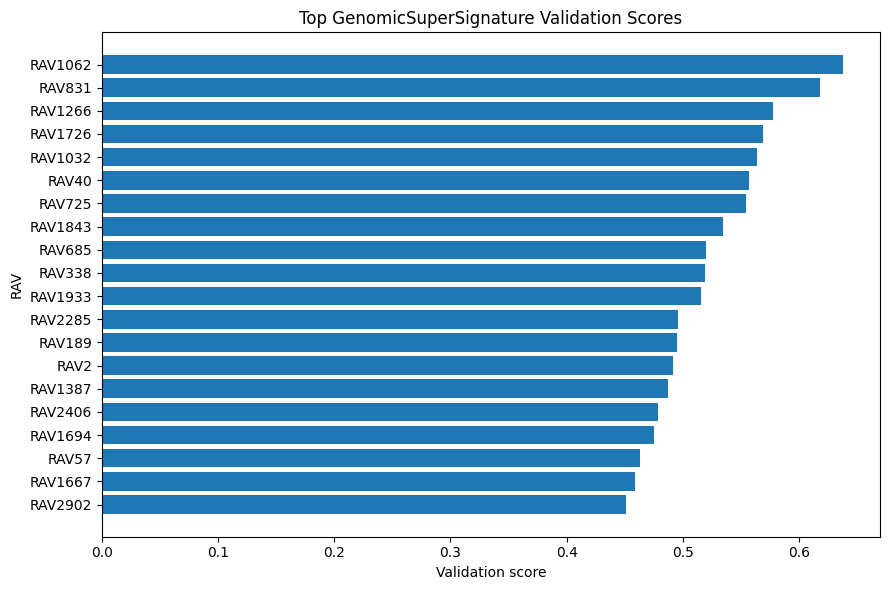

In [14]:
gss_validation_top20_df = gss_validation_df.sort_values("score", ascending=False).head(20).sort_values("score")

plt.figure(figsize=(9, 6))
plt.barh(gss_validation_top20_df["RAV"], gss_validation_top20_df["score"])
plt.xlabel("Validation score")
plt.ylabel("RAV")
plt.title("Top GenomicSuperSignature Validation Scores")
plt.tight_layout()
plt.show()

#### GenomicSuperSignature descriptive validation

The validation score is a GenomicSuperSignature-specific quality-control measure and should not be confused with the inner-cross-validation score used for predictive model selection.

Here, it measures the correlation between principal components of the institutional transcriptomic dataset and the pretrained RAVs. Higher values indicate stronger correspondence between the observed transcriptomic variation and a previously identified replicable axis of variation.

These scores are used only to assess the relevance of the transferred representation and are not used to select features for the oligometastatic/polymetastatic classifier.

#### Prepare GenomicSuperSignature features

We merge the GenomicSuperSignature scores with the existing metadata and target labels using `sample_id_normalised`.

Only columns starting with `gss__` are used as model features.

In [15]:
gss_model_df = metadata_df.merge(
    gss_scores_df,
    on="sample_id_normalised",
    how="inner"
)

thesis_print("GSS modelling dataframe shape:")
thesis_print(gss_model_df.shape)

thesis_print("\nTarget distribution after merge:")
thesis_display(gss_model_df[target_col].value_counts())

gss_feature_cols = [
    col for col in gss_model_df.columns
    if col.startswith("gss__")
]

X_gss = gss_model_df[gss_feature_cols].copy()
y_gss = gss_model_df[target_col].astype(int).copy()

gss_metadata_df = gss_model_df[
    ["sample_id_normalised", target_col]
].copy()

thesis_print("X_gss shape:")
thesis_print(X_gss.shape)

thesis_print("\ny_gss shape:")
thesis_print(y_gss.shape)

thesis_print("\nNumber of available GSS features:")
thesis_print(len(gss_feature_cols))

thesis_print("\nFirst GSS feature columns:")
thesis_print(gss_feature_cols[:10])

assert X_gss.shape[0] == y_gss.shape[0]
assert X_gss.shape[0] == gss_metadata_df.shape[0]
assert set(y_gss.unique()).issubset({0, 1})
assert X_gss.isna().sum().sum() == 0
assert gss_metadata_df["sample_id_normalised"].is_unique

thesis_display(X_gss.head())

GSS modelling dataframe shape:
(139, 4769)

Target distribution after merge:


Polymetastatic
1    85
0    54
Name: count, dtype: int64

X_gss shape:
(139, 4764)

y_gss shape:
(139,)

Number of available GSS features:
4764

First GSS feature columns:
['gss__RAV1', 'gss__RAV2', 'gss__RAV3', 'gss__RAV4', 'gss__RAV5', 'gss__RAV6', 'gss__RAV7', 'gss__RAV8', 'gss__RAV9', 'gss__RAV10']


,gss__RAV1,gss__RAV2,gss__RAV3,gss__RAV4,gss__RAV5,gss__RAV6,gss__RAV7,gss__RAV8,gss__RAV9,gss__RAV10,...,gss__RAV4755,gss__RAV4756,gss__RAV4757,gss__RAV4758,gss__RAV4759,gss__RAV4760,gss__RAV4761,gss__RAV4762,gss__RAV4763,gss__RAV4764
0,57.707,-48.145,14.073,-5.574,-1.654,-6.806,-4.628,12.500,21.835,7.058,...,-0.309,-0.881,-0.707,0.325,0.043,-0.443,-0.151,0.421,0.276,1.401
1,56.813,-35.735,15.366,-1.384,-11.155,-10.877,3.291,9.919,13.578,8.891,...,-0.777,-0.879,-0.193,-0.529,-0.406,-0.348,1.613,-0.721,-0.194,-0.550
2,77.456,-39.178,15.880,4.463,-8.110,-10.395,-5.836,6.216,9.606,11.202,...,0.623,-1.604,-1.295,0.647,0.353,2.677,0.524,-0.316,-1.713,1.004
3,60.374,-19.819,-4.930,-12.328,-6.422,-4.272,-0.729,2.379,11.220,3.704,...,1.426,-2.471,0.454,1.320,-0.063,2.406,2.394,-3.073,-0.778,-2.890
4,81.835,-41.727,7.904,-10.548,-4.957,-4.807,-4.341,14.635,21.901,9.186,...,0.183,-0.619,-1.304,0.473,0.152,2.921,1.066,-0.167,-2.507,-1.373


In [16]:
gss_classifiers = wrap_with_feature_selection(
    build_representation_classifiers(
        random_state=RANDOM_STATE,
        n_features=X_gss.shape[1],
        use_feature_selection=False,
    ),
    k_grid=[5, 10, 20, 50],
)

#### Evaluate GenomicSuperSignature

All available GenomicSuperSignature RAV scores are supplied to the downstream modelling pipeline.

Within each inner cross-validation loop, `SelectKBest` selects the number of retained RAV features from 5, 10, 20, and 50. Feature selection therefore uses only the training portion of each fold and cannot use information from the corresponding held-out outer fold.

The resulting representation is evaluated with the same three candidate classifiers used throughout the transcriptomics benchmark.


In [17]:
gss_results_dfs, gss_predictions_dfs = evaluate_tpm_representation(
    X=X_gss, y=y_gss, representation_base_name='genomic_super_signature', metadata_df=gss_metadata_df,
    outer_cv=outer_splits, inner_cv=inner_cv, scoring=scoring, output_dir=output_dir,
    classifiers=gss_classifiers, registry=tpm_registry, reference_metadata=metadata_df,
    reference_y=y, run_nested_cv=RUN_NESTED_CV,
)



genomic_super_signature_logreg_l1 | Outer fold 1


Best inner score:
0.460

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector__k': 5}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.495, 'f1': 0.444, 'f1_macro': 0.464, 'precision_poly': 0.6, 'sensitivity_poly': 0.353, 'recall_oligo': 0.636, 'roc_auc': 0.390, 'specificity_oligo': np.float64(0.636)}

genomic_super_signature_logreg_l1 | Outer fold 2


Best inner score:
0.449

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector__k': 50}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.503, 'f1': 0.7, 'f1_macro': 0.475, 'precision_poly': 0.609, 'sensitivity_poly': 0.824, 'recall_oligo': 0.182, 'roc_auc': 0.497, 'specificity_oligo': np.float64(0.182)}

genomic_super_signature_logreg_l1 | Outer fold 3


Best inner score:
0.543

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector__k': 50}

Test metrics:
{'accuracy': 0.393, 'balanced_accuracy': 0.356, 'f1': 0.514, 'f1_macro': 0.352, 'precision_poly': 0.5, 'sensitivity_poly': 0.529, 'recall_oligo': 0.182, 'roc_auc': 0.332, 'specificity_oligo': np.float64(0.182)}

genomic_super_signature_logreg_l1 | Outer fold 4


Best inner score:
0.509

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector__k': 50}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.447, 'f1': 0.545, 'f1_macro': 0.447, 'precision_poly': 0.562, 'sensitivity_poly': 0.529, 'recall_oligo': 0.364, 'roc_auc': 0.390, 'specificity_oligo': np.float64(0.364)}

genomic_super_signature_logreg_l1 | Outer fold 5


...

Best inner score:
0.532

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector__k': 50}

Test metrics:
{'accuracy': 0.393, 'balanced_accuracy': 0.468, 'f1': 0.190, 'f1_macro': 0.352, 'precision_poly': 0.5, 'sensitivity_poly': 0.118, 'recall_oligo': 0.818, 'roc_auc': 0.262, 'specificity_oligo': np.float64(0.818)}

genomic_super_signature_xgboost | Outer fold 2


Best inner score:
0.466

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 5}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.463, 'f1': 0.516, 'f1_macro': 0.458, 'precision_poly': 0.571, 'sensitivity_poly': 0.471, 'recall_oligo': 0.455, 'roc_auc': 0.449, 'specificity_oligo': np.float64(0.455)}

genomic_super_signature_xgboost | Outer fold 3


Best inner score:
0.618

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 5}

Test metrics:
{'accuracy': 0.429, 'balanced_accuracy': 0.385, 'f1': 0.556, 'f1_macro': 0.378, 'precision_poly': 0.526, 'sensitivity_poly': 0.588, 'recall_oligo': 0.182, 'roc_auc': 0.332, 'specificity_oligo': np.float64(0.182)}

genomic_super_signature_xgboost | Outer fold 4


Best inner score:
0.478

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 5}

Test metrics:
{'accuracy': 0.643, 'balanced_accuracy': 0.626, 'f1': 0.706, 'f1_macro': 0.626, 'precision_poly': 0.706, 'sensitivity_poly': 0.706, 'recall_oligo': 0.545, 'roc_auc': 0.529, 'specificity_oligo': np.float64(0.545)}

genomic_super_signature_xgboost | Outer fold 5


Best inner score:
0.579

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector__k': 5}

Test metrics:
{'accuracy': 0.444, 'balanced_accuracy': 0.476, 'f1': 0.444, 'f1_macro': 0.444, 'precision_poly': 0.6, 'sensitivity_poly': 0.353, 'recall_oligo': 0.6, 'roc_auc': 0.406, 'specificity_oligo': np.float64(0.6)}


### 2.4 MultiPLIER

MultiPLIER is a transfer-learning framework that represents transcriptomic samples through latent variables learned from large external gene-expression collections.

For this analysis, the main pretrained recount2 PLIER model was used rather than one of the subsampled sensitivity models included in the MultiPLIER repository. The pretrained model contains 987 latent variables derived from 6,750 genes.

Institutional transcriptomic features were mapped to gene symbols and aligned with the genes expected by the pretrained model. Multiple institutional features mapping to the same gene symbol were averaged before projection. Of the 6,750 genes represented in the pretrained model, 6,530 (96.7%) were available in the institutional expression matrix.

The institutional samples were then projected into the fixed pretrained latent-variable space using the MultiPLIER `GetNewDataB()` procedure. This produced 987 latent-variable features for each patient.

The resulting representation is evaluated below using the same nested cross-validation framework and classifier families as the other transcriptomic representations.

Paper: https://doi.org/10.1016/j.cels.2019.04.003

GitHub: https://github.com/greenelab/multi-plier

#### Load MultiPLIER scores

The recount2 MultiPLIER projection was generated externally in R using the pretrained model and the official MultiPLIER projection utility.

The resulting matrix contains one row per patient and 987 pretrained latent variables. The accompanying gene-overlap and run-summary files are loaded as quality-control information.

In [18]:
multiplier_output_dir = os.path.join(output_dir, "MultiPLIER")

multiplier_scores_path = os.path.join(
    multiplier_output_dir,
    "transcriptomics_multiplier_scores.csv",
)

multiplier_gene_overlap_summary_path = os.path.join(
    multiplier_output_dir,
    "transcriptomics_multiplier_gene_overlap_summary.csv",
)

multiplier_run_summary_path = os.path.join(
    multiplier_output_dir,
    "transcriptomics_multiplier_run_summary.csv",
)

thesis_print("MultiPLIER output directory:")
thesis_print(multiplier_output_dir)

thesis_print("\nFile checks:")
for path in [
    multiplier_scores_path,
    multiplier_gene_overlap_summary_path,
    multiplier_run_summary_path,
]:
    thesis_print(os.path.basename(path), "exists:", os.path.exists(path))

if not os.path.exists(multiplier_scores_path):
    raise FileNotFoundError(
        f"Could not find MultiPLIER scores: {multiplier_scores_path}"
    )

multiplier_scores_df = pd.read_csv(multiplier_scores_path)

thesis_print("\nMultiPLIER score matrix shape:")
thesis_print(multiplier_scores_df.shape)

thesis_display(multiplier_scores_df.head())

if os.path.exists(multiplier_gene_overlap_summary_path):
    multiplier_gene_overlap_summary_df = pd.read_csv(
        multiplier_gene_overlap_summary_path
    )
    thesis_print("\nMultiPLIER gene overlap summary:")
    thesis_display(multiplier_gene_overlap_summary_df)

if os.path.exists(multiplier_run_summary_path):
    multiplier_run_summary_df = pd.read_csv(
        multiplier_run_summary_path
    )
    thesis_print("\nMultiPLIER run summary:")
    thesis_display(multiplier_run_summary_df)

MultiPLIER output directory:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/MultiPLIER

File checks:
transcriptomics_multiplier_scores.csv exists: True
transcriptomics_multiplier_gene_overlap_summary.csv exists: True
transcriptomics_multiplier_run_summary.csv exists: True

MultiPLIER score matrix shape:
(139, 988)


,sample_id_normalised,multiplier__1_REACTOME_MRNA_SPLICING,multiplier__2_SVM_Monocytes,multiplier__3_REACTOME_TRANSMISSION_ACROSS_CHEMICAL_SYNAPSES,multiplier__4_REACTOME_NEURONAL_SYSTEM,multiplier__LV_5,multiplier__LV_6,multiplier__7_IRIS_Neutrophil_Resting,multiplier__8_KEGG_PPAR_SIGNALING_PATHWAY,multiplier__LV_9,...,multiplier__LV_978,multiplier__LV_979,multiplier__LV_980,multiplier__LV_981,multiplier__LV_982,multiplier__LV_983,multiplier__LV_984,multiplier__985_IRIS_Neutrophil_Resting,multiplier__LV_986,multiplier__LV_987
0,101B,0.078,-0.043,0.000,-0.046,0.027,0.025,0.013,0.034,0.019,...,0.007,-0.018,0.008,0.028,0.038,0.006,0.062,-0.015,-0.019,-0.005
1,108B,0.064,0.006,0.024,0.008,0.014,-0.012,0.032,0.048,0.052,...,-0.032,0.007,-0.008,-0.011,-0.008,-0.001,-0.051,-0.022,-0.029,-0.032
2,10B,0.096,0.024,0.066,-0.012,0.032,0.067,0.031,0.028,0.027,...,-0.004,-0.001,0.011,0.001,0.005,-0.001,0.009,-0.041,0.008,-0.006
3,110B,-0.034,0.022,0.039,0.026,0.004,0.003,0.002,0.033,0.014,...,-0.000,0.055,0.002,0.002,0.007,0.035,0.062,0.038,0.048,-0.040
4,115B,0.023,0.057,0.058,0.006,0.001,0.005,0.009,0.016,-0.001,...,0.027,-0.012,-0.007,-0.001,0.004,0.022,-0.021,0.070,0.009,-0.072



MultiPLIER gene overlap summary:


,model,n_expression_genes_with_symbols,n_multiplier_model_genes,n_common_genes_before_variance_filter,n_zero_variance_genes_removed,n_genes_used_for_projection,fraction_expression_genes_in_multiplier,fraction_multiplier_genes_available
0,pretrained_recount2_MultiPLIER,18260,6750,6530,0,6530,0.358,0.967



MultiPLIER run summary:


,model,model_path,plier_util_path,n_samples,n_expression_genes_with_symbols,n_multiplier_model_genes,n_common_genes_before_variance_filter,n_zero_variance_genes_removed,n_genes_used_for_projection,n_latent_variables,scores_output_path,gene_overlap_output_path
0,pretrained_recount2_MultiPLIER,/mnt/data3/MCPP-Breast/Machine-Learning-Models...,/mnt/data3/MCPP-Breast/Machine-Learning-Models...,139,18260,6750,6530,0,6530,987,/mnt/data3/MCPP-Breast/Machine-Learning-Models...,/mnt/data3/MCPP-Breast/Machine-Learning-Models...


#### Prepare MultiPLIER features

The MultiPLIER latent-variable scores are merged with the transcriptomics metadata using `sample_id_normalised`.

Only columns starting with `multiplier__` are used as predictive features. The sample identifier and metastatic-group label are retained only as metadata.

The resulting representation contains 987 externally learned latent variables per patient.

In [19]:
multiplier_model_df = metadata_df.merge(
    multiplier_scores_df,
    on="sample_id_normalised",
    how="inner",
    validate="one_to_one",
)

multiplier_feature_cols = [
    col for col in multiplier_model_df.columns
    if col.startswith("multiplier__")
]

X_multiplier = multiplier_model_df[multiplier_feature_cols].copy()
y_multiplier = multiplier_model_df[target_col].astype(int).copy()

multiplier_metadata_df = multiplier_model_df[
    ["sample_id_normalised", target_col]
].copy()

thesis_print("MultiPLIER modelling dataframe shape:")
thesis_print(multiplier_model_df.shape)

thesis_print("\nX_multiplier shape:")
thesis_print(X_multiplier.shape)

thesis_print("\ny_multiplier shape:")
thesis_print(y_multiplier.shape)

thesis_print("\nNumber of MultiPLIER latent variables:")
thesis_print(len(multiplier_feature_cols))

thesis_print("\nTarget distribution:")
thesis_display(y_multiplier.value_counts())

assert X_multiplier.shape == (139, 987)
assert X_multiplier.shape[0] == y_multiplier.shape[0]
assert multiplier_metadata_df["sample_id_normalised"].is_unique
assert X_multiplier.isna().sum().sum() == 0
assert np.isfinite(X_multiplier.to_numpy()).all()
assert set(y_multiplier.unique()).issubset({0, 1})

thesis_display(X_multiplier.head())

MultiPLIER modelling dataframe shape:
(139, 992)

X_multiplier shape:
(139, 987)

y_multiplier shape:
(139,)

Number of MultiPLIER latent variables:
987

Target distribution:


Polymetastatic
1    85
0    54
Name: count, dtype: int64

,multiplier__1_REACTOME_MRNA_SPLICING,multiplier__2_SVM_Monocytes,multiplier__3_REACTOME_TRANSMISSION_ACROSS_CHEMICAL_SYNAPSES,multiplier__4_REACTOME_NEURONAL_SYSTEM,multiplier__LV_5,multiplier__LV_6,multiplier__7_IRIS_Neutrophil_Resting,multiplier__8_KEGG_PPAR_SIGNALING_PATHWAY,multiplier__LV_9,multiplier__10_SVM_Macrophages_M0,...,multiplier__LV_978,multiplier__LV_979,multiplier__LV_980,multiplier__LV_981,multiplier__LV_982,multiplier__LV_983,multiplier__LV_984,multiplier__985_IRIS_Neutrophil_Resting,multiplier__LV_986,multiplier__LV_987
0,0.078,-0.043,0.000,-0.046,0.027,0.025,0.013,0.034,0.019,0.082,...,0.007,-0.018,0.008,0.028,0.038,0.006,0.062,-0.015,-0.019,-0.005
1,0.064,0.006,0.024,0.008,0.014,-0.012,0.032,0.048,0.052,0.000,...,-0.032,0.007,-0.008,-0.011,-0.008,-0.001,-0.051,-0.022,-0.029,-0.032
2,0.096,0.024,0.066,-0.012,0.032,0.067,0.031,0.028,0.027,0.052,...,-0.004,-0.001,0.011,0.001,0.005,-0.001,0.009,-0.041,0.008,-0.006
3,-0.034,0.022,0.039,0.026,0.004,0.003,0.002,0.033,0.014,-0.007,...,-0.000,0.055,0.002,0.002,0.007,0.035,0.062,0.038,0.048,-0.040
4,0.023,0.057,0.058,0.006,0.001,0.005,0.009,0.016,-0.001,0.025,...,0.027,-0.012,-0.007,-0.001,0.004,0.022,-0.021,0.070,0.009,-0.072


In [20]:
multiplier_classifiers = wrap_with_feature_selection(
    build_representation_classifiers(
        random_state=RANDOM_STATE,
        n_features=X_multiplier.shape[1],
        use_feature_selection=False,
    ),
    k_grid=[10, 20, 50, 100],
)

#### Evaluate MultiPLIER

The MultiPLIER representation contains 987 latent variables, which is large relative to the cohort size.

To avoid fixing an arbitrary number of latent variables before model evaluation, supervised feature selection is included inside the nested cross-validation pipeline. `SelectKBest` evaluates candidate subsets of 10, 20, 50, and 100 latent variables using only the training portion of each inner-CV fold.

The selected latent variables are then passed to the same candidate classifier families used for the other transcriptomic representations. Outer-fold data remain completely excluded from feature selection and hyperparameter tuning.

In [21]:
multiplier_results_dfs, multiplier_predictions_dfs = evaluate_tpm_representation(
    X=X_multiplier, y=y_multiplier, representation_base_name='multiplier', metadata_df=multiplier_metadata_df,
    outer_cv=outer_splits, inner_cv=inner_cv, scoring=scoring, output_dir=output_dir,
    classifiers=multiplier_classifiers, registry=tpm_registry, reference_metadata=metadata_df,
    reference_y=y, run_nested_cv=RUN_NESTED_CV,
)



multiplier_logreg_l1 | Outer fold 1


Best inner score:
0.544

Best params:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'sampler': 'passthrough', 'selector__k': 100}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.599, 'f1': 0.571, 'f1_macro': 0.571, 'precision_poly': 0.727, 'sensitivity_poly': 0.471, 'recall_oligo': 0.727, 'roc_auc': 0.636, 'specificity_oligo': np.float64(0.727)}

multiplier_logreg_l1 | Outer fold 2


Best inner score:
0.482

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector__k': 100}

Test metrics:
{'accuracy': 0.607, 'balanced_accuracy': 0.628, 'f1': 0.621, 'f1_macro': 0.607, 'precision_poly': 0.75, 'sensitivity_poly': 0.529, 'recall_oligo': 0.727, 'roc_auc': 0.636, 'specificity_oligo': np.float64(0.727)}

multiplier_logreg_l1 | Outer fold 3


Best inner score:
0.557

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector__k': 20}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.535, 'f1': 0.667, 'f1_macro': 0.533, 'precision_poly': 0.632, 'sensitivity_poly': 0.706, 'recall_oligo': 0.364, 'roc_auc': 0.433, 'specificity_oligo': np.float64(0.364)}

multiplier_logreg_l1 | Outer fold 4


Best inner score:
0.533

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector__k': 50}

Test metrics:
{'accuracy': 0.643, 'balanced_accuracy': 0.578, 'f1': 0.75, 'f1_macro': 0.562, 'precision_poly': 0.652, 'sensitivity_poly': 0.882, 'recall_oligo': 0.273, 'roc_auc': 0.535, 'specificity_oligo': np.float64(0.273)}

multiplier_logreg_l1 | Outer fold 5


...

Best inner score:
0.539

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 50}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.599, 'f1': 0.571, 'f1_macro': 0.571, 'precision_poly': 0.727, 'sensitivity_poly': 0.471, 'recall_oligo': 0.727, 'roc_auc': 0.615, 'specificity_oligo': np.float64(0.727)}

multiplier_xgboost | Outer fold 2


Best inner score:
0.497

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector__k': 100}

Test metrics:
{'accuracy': 0.607, 'balanced_accuracy': 0.580, 'f1': 0.686, 'f1_macro': 0.581, 'precision_poly': 0.667, 'sensitivity_poly': 0.706, 'recall_oligo': 0.455, 'roc_auc': 0.586, 'specificity_oligo': np.float64(0.455)}

multiplier_xgboost | Outer fold 3


Best inner score:
0.637

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 50}

Test metrics:
{'accuracy': 0.357, 'balanced_accuracy': 0.310, 'f1': 0.5, 'f1_macro': 0.3, 'precision_poly': 0.474, 'sensitivity_poly': 0.529, 'recall_oligo': 0.091, 'roc_auc': 0.246, 'specificity_oligo': np.float64(0.091)}

multiplier_xgboost | Outer fold 4


Best inner score:
0.575

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 100}

Test metrics:
{'accuracy': 0.536, 'balanced_accuracy': 0.489, 'f1': 0.649, 'f1_macro': 0.482, 'precision_poly': 0.6, 'sensitivity_poly': 0.706, 'recall_oligo': 0.273, 'roc_auc': 0.481, 'specificity_oligo': np.float64(0.273)}

multiplier_xgboost | Outer fold 5


Best inner score:
0.581

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector__k': 20}

Test metrics:
{'accuracy': 0.444, 'balanced_accuracy': 0.435, 'f1': 0.516, 'f1_macro': 0.432, 'precision_poly': 0.571, 'sensitivity_poly': 0.471, 'recall_oligo': 0.4, 'roc_auc': 0.482, 'specificity_oligo': np.float64(0.4)}


### 2.5 Frozen Tybalt encoders

Tybalt is a variational autoencoder-based pan-cancer transcriptomic representation pretrained on TCGA RNA-seq data.

Three published pretrained Tybalt encoders are evaluated:

- `onehidden`;
- `twohidden100`;
- `twohidden300`.

Each encoder receives the same ordered set of 5,000 genes and maps each sample into a lower-dimensional latent representation.

The pretrained encoder weights are fixed and are never updated using the institutional cohort or the oligometastatic/polymetastatic labels.

The original Tybalt input data were scaled gene-wise to the [0, 1] range. Because the fitted TCGA scaling object is not available for direct reuse, institutional MinMax scaling is performed inside the nested cross-validation pipeline. The scaler is therefore fitted only on the training samples of each fold and then applied to validation or test samples before projection through the frozen encoder. Values outside the training-fold range are clipped to [0, 1].

This prevents held-out samples from influencing preprocessing parameters.

The resulting latent features are then standardised and evaluated using the same downstream classifier families, optional SMOTE resampling, and nested cross-validation framework used for the other transcriptomic representations.

The external preparation script only aligns the institutional transcriptomic matrix to the 5,000-gene Tybalt input space. It does not generate predictive latent representations on the full cohort.

Paper: https://doi.org/10.1142/9789813235533_0008

GitHub: https://github.com/greenelab/tybalt

In [22]:
tybalt_output_dir = os.path.join(
    output_dir,
    "Tybalt",
)

tybalt_aligned_input_path = os.path.join(
    tybalt_output_dir,
    "transcriptomics_tybalt_aligned_input.csv",
)

tybalt_gene_overlap_summary_path = os.path.join(
    tybalt_output_dir,
    "transcriptomics_tybalt_gene_overlap_summary.csv",
)

tybalt_run_summary_path = os.path.join(
    tybalt_output_dir,
    "transcriptomics_tybalt_run_summary.csv",
)

for path in [
    tybalt_aligned_input_path,
    tybalt_gene_overlap_summary_path,
    tybalt_run_summary_path,
]:
    thesis_print(os.path.basename(path), "exists:", os.path.exists(path))

tybalt_aligned_input_df = pd.read_csv(
    tybalt_aligned_input_path
)

thesis_print("\nTybalt aligned input shape:")
thesis_print(tybalt_aligned_input_df.shape)

assert tybalt_aligned_input_df.shape == (139, 5001)
assert tybalt_aligned_input_df["sample_id_normalised"].is_unique

tybalt_gene_cols = [
    col
    for col in tybalt_aligned_input_df.columns
    if col != "sample_id_normalised"
]

assert len(tybalt_gene_cols) == 5000
assert not tybalt_aligned_input_df[tybalt_gene_cols].isna().any().any()
assert np.isfinite(
    tybalt_aligned_input_df[tybalt_gene_cols].to_numpy()
).all()

tybalt_gene_overlap_summary_df = pd.read_csv(
    tybalt_gene_overlap_summary_path
)

tybalt_run_summary_df = pd.read_csv(
    tybalt_run_summary_path
)

thesis_print("\nTybalt gene overlap summary:")
thesis_display(tybalt_gene_overlap_summary_df)

thesis_print("\nTybalt run summary:")
thesis_display(tybalt_run_summary_df)

transcriptomics_tybalt_aligned_input.csv exists: True
transcriptomics_tybalt_gene_overlap_summary.csv exists: True
transcriptomics_tybalt_run_summary.csv exists: True



Tybalt aligned input shape:
(139, 5001)

Tybalt gene overlap summary:


,n_tybalt_input_genes,n_expression_genes_with_symbols,n_common_genes,n_missing_tybalt_genes,fraction_tybalt_genes_available
0,5000,18260,4294,706,0.859



Tybalt run summary:


,n_samples,n_tybalt_input_genes,n_common_genes,n_missing_tybalt_genes,input_scaling,onehidden_model_path,twohidden100_model_path,twohidden300_model_path,aligned_input_path
0,139,5000,4294,706,none; fold-specific MinMax scaling is performe...,/home/martapimentel/external/tybalt/models/enc...,/home/martapimentel/external/tybalt/models/enc...,/home/martapimentel/external/tybalt/models/enc...,/mnt/data3/MCPP-Breast/Machine-Learning-Models...


#### Evaluate Tybalt representations

Each Tybalt encoder produces 100 latent features per sample. These representations are evaluated separately using the same nested cross-validation framework used for gene-level expression, PCA, GenomicSuperSignature, and MultiPLIER.

For each Tybalt representation, three candidate classifiers (L1 logistic regression, Random Forest, and XGBoost) are evaluated.

In [23]:
tybalt_model_df = metadata_df[
    ["sample_id_normalised", target_col]
].merge(
    tybalt_aligned_input_df,
    on="sample_id_normalised",
    how="inner",
    validate="one_to_one",
)

X_tybalt = tybalt_model_df[
    tybalt_gene_cols
].copy()

y_tybalt = tybalt_model_df[
    target_col
].astype(int).copy()

tybalt_metadata_df = tybalt_model_df[
    ["sample_id_normalised", target_col]
].copy()

assert X_tybalt.shape == (139, 5000)
assert len(y_tybalt) == 139
assert X_tybalt.index.equals(y_tybalt.index)

thesis_print("X_tybalt shape:")
thesis_print(X_tybalt.shape)

thesis_print("\nTarget distribution:")
thesis_display(y_tybalt.value_counts().sort_index())

X_tybalt shape:
(139, 5000)

Target distribution:


Polymetastatic
0    54
1    85
Name: count, dtype: int64

In [24]:
tybalt_repo_dir = Path(
    "/home/martapimentel/external/tybalt"
)

tybalt_model_paths = {
    "onehidden": (
        tybalt_repo_dir
        / "models"
        / "encoder_onehidden_vae.hdf5"
    ),
    "twohidden100": (
        tybalt_repo_dir
        / "models"
        / "encoder_twohidden100_vae.hdf5"
    ),
    "twohidden300": (
        tybalt_repo_dir
        / "models"
        / "encoder_twohidden300_vae.hdf5"
    ),
}

for name, path in tybalt_model_paths.items():
    thesis_print(name, path)
    assert path.exists(), f"Missing Tybalt encoder: {path}"

onehidden /home/martapimentel/external/tybalt/models/encoder_onehidden_vae.hdf5
twohidden100 /home/martapimentel/external/tybalt/models/encoder_twohidden100_vae.hdf5
twohidden300 /home/martapimentel/external/tybalt/models/encoder_twohidden300_vae.hdf5


In [25]:
tybalt_results_dfs = {}
tybalt_predictions_dfs = {}

for tybalt_name, model_path in tybalt_model_paths.items():
    thesis_print("\n" + "=" * 80)
    thesis_print(f"Evaluating Tybalt: {tybalt_name}")
    thesis_print("=" * 80)

    tybalt_classifiers = wrap_with_tybalt(
        classifiers=build_representation_classifiers(
            random_state=RANDOM_STATE,
            n_features=X_tybalt.shape[1],
            use_feature_selection=False,
        ),
        model_path=model_path,
    )

    results_dfs, predictions_dfs = (
        evaluate_tpm_representation(
            X=X_tybalt,
            y=y_tybalt,
            representation_base_name=f"tybalt_{tybalt_name}",
            metadata_df=tybalt_metadata_df,
            outer_cv=outer_splits,
            inner_cv=inner_cv,
            scoring=scoring,
            output_dir=output_dir,
            registry=tpm_registry, reference_metadata=metadata_df, reference_y=y,
            run_nested_cv=RUN_NESTED_CV,
            classifiers=tybalt_classifiers,
            n_jobs=1,
        )
    )

    tybalt_results_dfs.update(results_dfs)
    tybalt_predictions_dfs.update(predictions_dfs)



Evaluating Tybalt: onehidden

tybalt_onehidden_logreg_l1 | Outer fold 1


E0000 00:00:1789083003.317 3909377 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Best inner score:
0.474

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.536, 'balanced_accuracy': 0.553, 'f1': 0.552, 'f1_macro': 0.535, 'precision_poly': 0.667, 'sensitivity_poly': 0.471, 'recall_oligo': 0.636, 'roc_auc': 0.588, 'specificity_oligo': np.float64(0.636)}

tybalt_onehidden_logreg_l1 | Outer fold 2


Best inner score:
0.549

Best params:
{'classifier__C': 1, 'classifier__class_weight': None, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.535, 'f1': 0.667, 'f1_macro': 0.533, 'precision_poly': 0.632, 'sensitivity_poly': 0.706, 'recall_oligo': 0.364, 'roc_auc': 0.487, 'specificity_oligo': np.float64(0.364)}

tybalt_onehidden_logreg_l1 | Outer fold 3


Best inner score:
0.584

Best params:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'sampler': 'passthrough', 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.414, 'f1': 0.595, 'f1_macro': 0.403, 'precision_poly': 0.55, 'sensitivity_poly': 0.647, 'recall_oligo': 0.182, 'roc_auc': 0.380, 'specificity_oligo': np.float64(0.182)}

tybalt_onehidden_logreg_l1 | Outer fold 4


...

Best inner score:
0.539

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.495, 'f1': 0.444, 'f1_macro': 0.464, 'precision_poly': 0.6, 'sensitivity_poly': 0.353, 'recall_oligo': 0.636, 'roc_auc': 0.551, 'specificity_oligo': np.float64(0.636)}

tybalt_twohidden300_xgboost | Outer fold 2


Best inner score:
0.495

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.567, 'f1': 0.625, 'f1_macro': 0.562, 'precision_poly': 0.667, 'sensitivity_poly': 0.588, 'recall_oligo': 0.545, 'roc_auc': 0.570, 'specificity_oligo': np.float64(0.545)}

tybalt_twohidden300_xgboost | Outer fold 3


Best inner score:
0.545

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 0, 'classifier__reg_lambda': 5, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.571, 'balanced_accuracy': 0.535, 'f1': 0.667, 'f1_macro': 0.533, 'precision_poly': 0.632, 'sensitivity_poly': 0.706, 'recall_oligo': 0.364, 'roc_auc': 0.465, 'specificity_oligo': np.float64(0.364)}

tybalt_twohidden300_xgboost | Outer fold 4


Best inner score:
0.527

Best params:
{'classifier__colsample_bytree': 0.05, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 50, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.8, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.464, 'balanced_accuracy': 0.430, 'f1': 0.571, 'f1_macro': 0.429, 'precision_poly': 0.556, 'sensitivity_poly': 0.588, 'recall_oligo': 0.273, 'roc_auc': 0.369, 'specificity_oligo': np.float64(0.273)}

tybalt_twohidden300_xgboost | Outer fold 5


Best inner score:
0.548

Best params:
{'classifier__colsample_bytree': 0.1, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 1, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 30, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 1, 'classifier__subsample': 0.6, 'sampler': SMOTE(random_state=42), 'selector': 'passthrough'}

Test metrics:
{'accuracy': 0.481, 'balanced_accuracy': 0.465, 'f1': 0.562, 'f1_macro': 0.463, 'precision_poly': 0.6, 'sensitivity_poly': 0.529, 'recall_oligo': 0.4, 'roc_auc': 0.412, 'specificity_oligo': np.float64(0.4)}


#### Full-cohort Tybalt projections for descriptive visualisation

For exploratory visualisation only, the complete institutional cohort is also projected into each pretrained Tybalt latent space.

For these exploratory projections, MinMax scaling is fitted using the full institutional cohort before applying the frozen pretrained encoder. Because this preprocessing uses all samples, these latent representations are not used for predictive modelling, model selection, hyperparameter tuning, or performance estimation.

They are used exclusively for descriptive silhouette scores and UMAP visualisations.

In [2]:
if RUN_EXPLORATORY:
    tybalt_exploratory_X_dfs = {}
    tybalt_exploratory_y_series = {}

    for tybalt_name, model_path in tybalt_model_paths.items():
        thesis_print("\n" + "=" * 80)
        thesis_print(f"Exploratory full-cohort Tybalt projection: {tybalt_name}")
        thesis_print("=" * 80)

        tybalt_transformer = TybaltEncoderTransformer(
            model_path=str(model_path),
            batch_size=32,
            clip=True,
        )

        latent_scores = tybalt_transformer.fit_transform(
            X_tybalt
        )

        latent_feature_cols = [
            f"{tybalt_name}__latent_{i + 1:03d}"
            for i in range(latent_scores.shape[1])
        ]

        X_tybalt_exploratory = pd.DataFrame(
            latent_scores,
            columns=latent_feature_cols,
            index=X_tybalt.index,
        )

        assert X_tybalt_exploratory.shape[0] == X_tybalt.shape[0]
        assert not X_tybalt_exploratory.isna().any().any()
        assert np.isfinite(
            X_tybalt_exploratory.to_numpy()
        ).all()

        tybalt_exploratory_X_dfs[
            tybalt_name
        ] = X_tybalt_exploratory

        tybalt_exploratory_y_series[
            tybalt_name
        ] = y_tybalt.copy()

        thesis_print(
            "Latent representation shape:",
            X_tybalt_exploratory.shape,
        )
else:
    thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")



Exploratory full-cohort Tybalt projection: onehidden


E0000 00:00:1790023543.937 1954919 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Latent representation shape: (139, 100)

Exploratory full-cohort Tybalt projection: twohidden100


Latent representation shape: (139, 100)

Exploratory full-cohort Tybalt projection: twohidden300


Latent representation shape: (139, 100)


## 3. Exploratory representation geometry

In addition to supervised classification performance, the structure of each transcriptomics representation is examined using silhouette scores and two-dimensional UMAP visualisations.

The silhouette score uses oligometastatic and polymetastatic labels only to quantify how well the two groups are separated in each representation space. Values closer to 1 indicate stronger within-group cohesion and between-group separation, values around 0 indicate substantial overlap, and negative values indicate that samples tend to lie closer to the opposite group than to their assigned group.

UMAP is used as a complementary exploratory visualisation of local structure in each representation. The resulting two-dimensional projections are coloured by oligometastatic/polymetastatic status to assess whether visually distinct regions or gradients are apparent.

These analyses are exploratory only. Neither silhouette scores nor UMAP visualisations are used for representation selection, classifier selection, or predictive performance estimation.

In [3]:
if RUN_EXPLORATORY:
    silhouette_rows = []

    silhouette_rows.append(
        compute_representation_silhouette(
            X=X,
            y=y,
            representation_name="Gene-level expression",
            scale=True,
        )
    )

    pca_feature_cols = [col for col in pca_scores_df.columns if col.startswith("PC")]

    silhouette_rows.append(
        compute_representation_silhouette(
            X=pca_scores_df[pca_feature_cols],
            y=y,
            representation_name="PCA",
            scale=False,
        )
    )

    silhouette_rows.append(
        compute_representation_silhouette(
            X=X_gss,
            y=y_gss,
            representation_name="GenomicSuperSignature",
            scale=True,
        )
    )

    silhouette_rows.append(
        compute_representation_silhouette(
            X=X_multiplier,
            y=y_multiplier,
            representation_name="MultiPLIER",
            scale=True,
        )
    )

    for tybalt_name, X_tybalt_repr in tybalt_exploratory_X_dfs.items():
        silhouette_rows.append(
            compute_representation_silhouette(
                X=X_tybalt_repr,
                y=tybalt_exploratory_y_series[tybalt_name],
                representation_name=f"Tybalt {tybalt_name}",
                scale=True,
            )
        )

    silhouette_df = pd.DataFrame(silhouette_rows).sort_values(
        "silhouette_score",
        ascending=False,
    ).reset_index(drop=True)

    thesis_display(silhouette_df)

    silhouette_df.to_csv(
        os.path.join(output_dir, "transcriptomics_representation_silhouette_scores.csv"),
        index=False,
    )
else:
    thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")


,representation,silhouette_score,n_samples,n_features
0,Tybalt twohidden100,0.008,139,100
1,Tybalt twohidden300,4.69e-4,139,100
2,PCA,-8.00e-6,139,20
3,Gene-level expression,-0.001,139,18260
4,MultiPLIER,-0.002,139,987
5,Tybalt onehidden,-0.003,139,100
6,GenomicSuperSignature,-0.006,139,4764


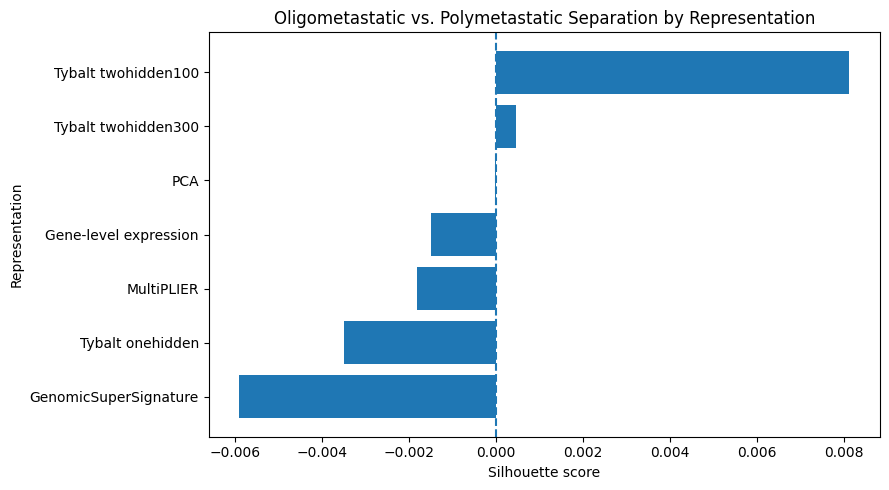

In [4]:
if RUN_EXPLORATORY:
    silhouette_plot_df = silhouette_df.sort_values("silhouette_score")

    plt.figure(figsize=(9, 5))
    plt.barh(
        silhouette_plot_df["representation"],
        silhouette_plot_df["silhouette_score"],
    )
    plt.axvline(0, linestyle="--")
    plt.xlabel("Silhouette score")
    plt.ylabel("Representation")
    plt.title("Oligometastatic vs. Polymetastatic Separation by Representation")
    plt.tight_layout()
    plt.show()
else:
    thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")


### Silhouette interpretation

The saved silhouette scores range from −0.005903426843730963 (GenomicSuperSignature) to 0.00813494436442852 (Tybalt twohidden100). All are near zero, indicating substantial geometric overlap and little separation of the oligo and poly groups in these spaces.

Group labels are the observed oligometastatic/polymetastatic classes, not assignments from an unsupervised clustering algorithm. The scores are descriptive and do not select representations or models. Weak geometric separation does not necessarily preclude supervised predictive signal; it also does not provide evidence of clinically useful discrimination. The small differences between these scores should not be overinterpreted.


### UMAP visualisation

UMAP projections are generated independently for each transcriptomics representation. Each projection uses the full available representation matrix and is therefore intended solely for exploratory visualisation.

Because UMAP is a non-linear dimensionality-reduction method and its geometry depends on parameters such as the number of neighbours and minimum distance, visual separation should not be interpreted as evidence of predictive performance. The plots are used only to complement the quantitative silhouette analysis and the subsequent nested-cross-validation results.

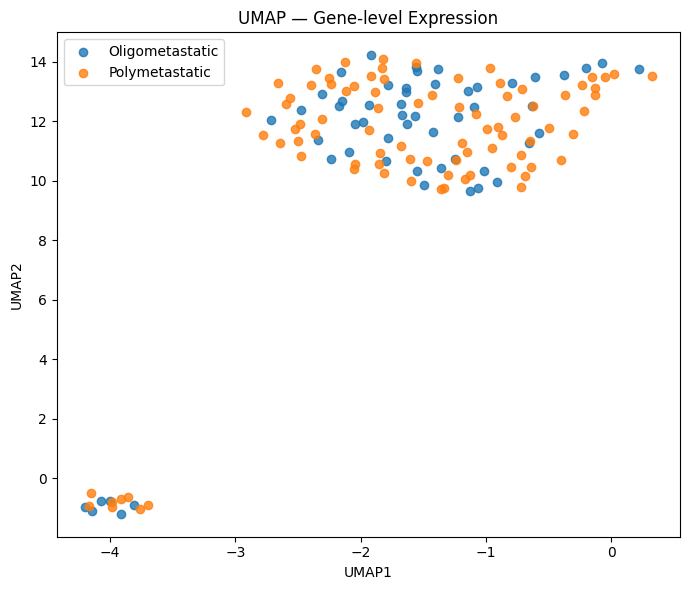

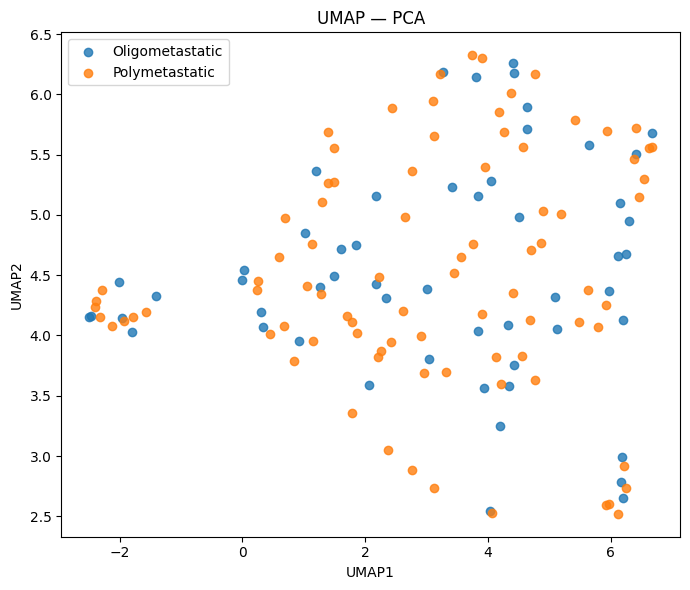

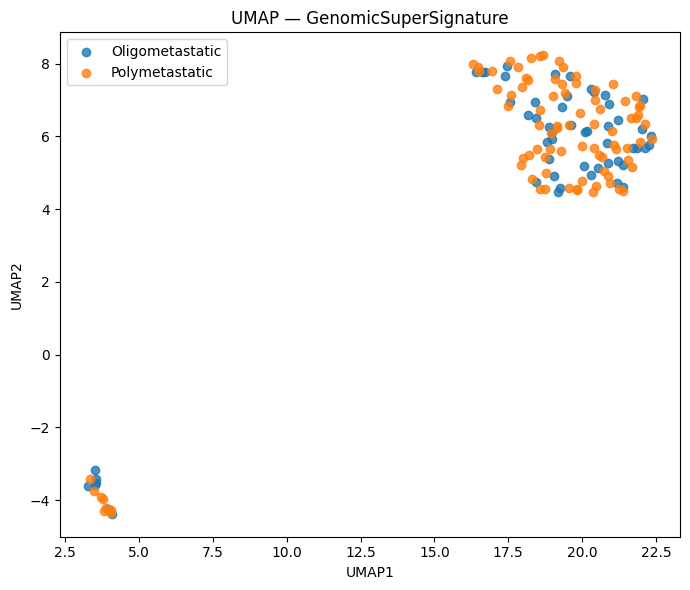

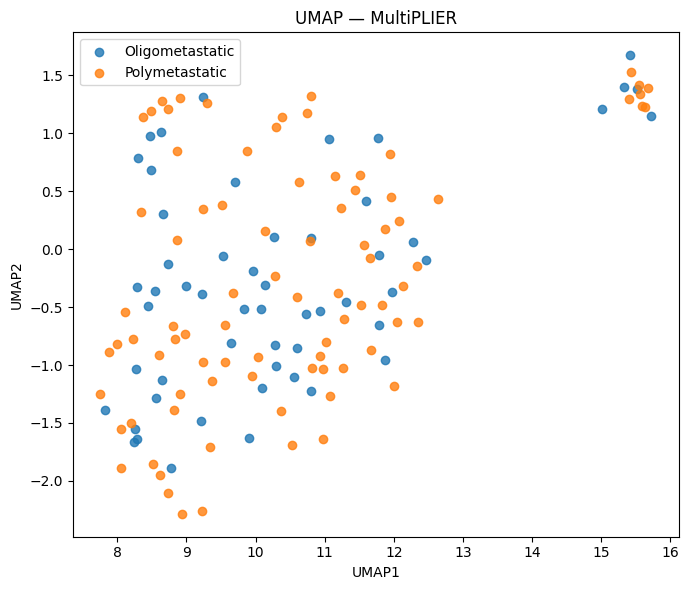

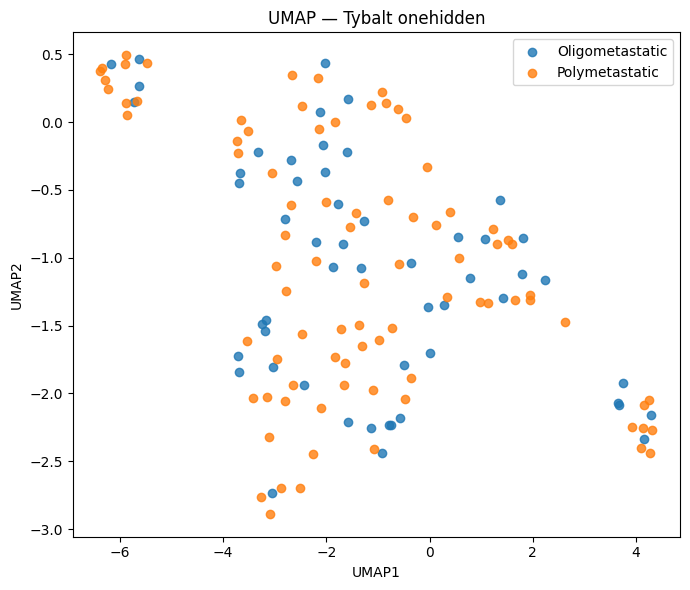

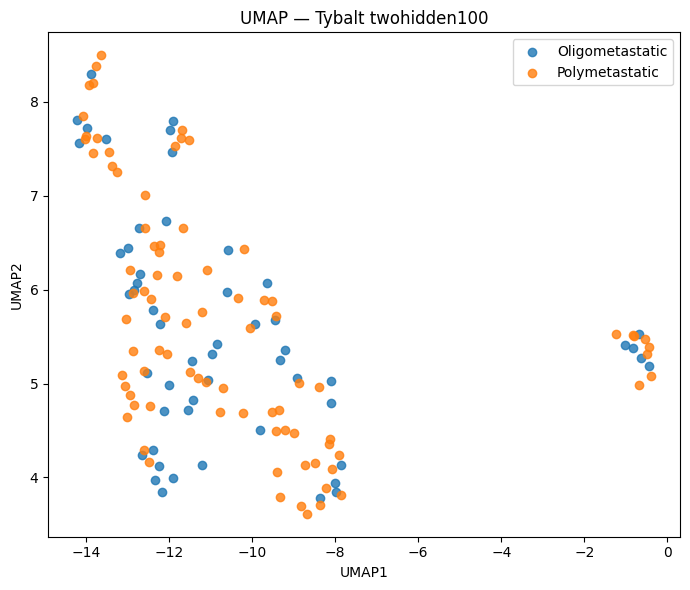

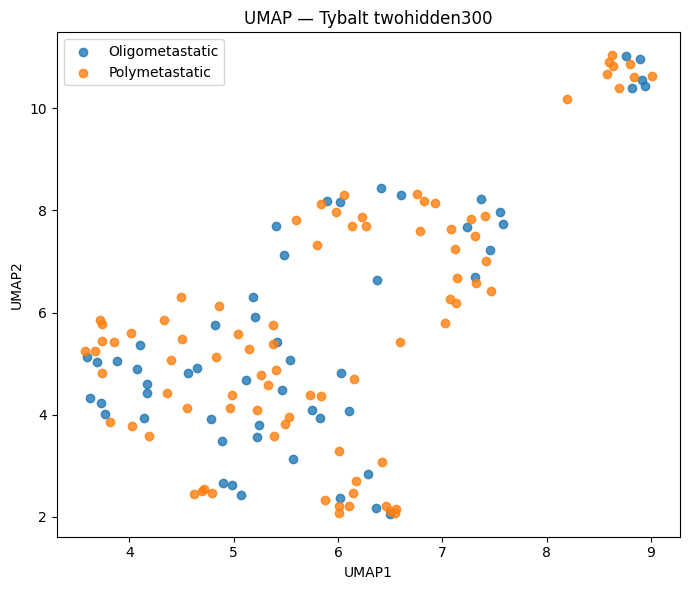

In [5]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"^n_jobs value 1 overridden to 1 by setting random_state\. Use no seed for parallelism\.$",
        category=UserWarning,
        module=r"^umap\.umap_$",
    )
    if RUN_EXPLORATORY:
        umap_outputs = {}

        umap_outputs["gene_level"] = plot_umap_representation(
            X=X,
            y=y,
            representation_name="Gene-level Expression",
            random_state=RANDOM_STATE,
            scale=True,
        )

        umap_outputs["pca"] = plot_umap_representation(
            X=pca_scores_df[pca_feature_cols],
            y=y,
            representation_name="PCA",
            random_state=RANDOM_STATE,
            scale=False,
        )

        umap_outputs["gss"] = plot_umap_representation(
            X=X_gss,
            y=y_gss,
            representation_name="GenomicSuperSignature",
            random_state=RANDOM_STATE,
            scale=True,
        )

        umap_outputs["multiplier"] = plot_umap_representation(
            X=X_multiplier,
            y=y_multiplier,
            representation_name="MultiPLIER",
            random_state=RANDOM_STATE,
            scale=True,
        )

        for tybalt_name, X_tybalt_repr in tybalt_exploratory_X_dfs.items():
            umap_outputs[f"tybalt_{tybalt_name}"] = (
                plot_umap_representation(
                    X=X_tybalt_repr,
                    y=tybalt_exploratory_y_series[tybalt_name],
                    representation_name=f"Tybalt {tybalt_name}",
                    random_state=RANDOM_STATE,
                    scale=True,
                )
            )
    else:
        thesis_print("Exploratory computation disabled; preserved notebook output predates this revision.")


## 4. Predictive comparison and held-out evaluation

The table separates held-out performance (`test`) from training diagnostics.

- **`mean_inner_cv_score`**: the internal cross-validation score (macro-F1) used to select hyperparameters — not the same as a training metric, since it is calculated on data held out during that part of the tuning process.
- **`mean_test_roc_auc`** and **`mean_test_balanced_accuracy`**: the main metrics, calculated on unseen data (outer-fold test).
- **`mean_train_roc_auc`**: included only as an overfitting diagnostic — it is calculated with the final model evaluated on the same data it was trained on, so it is always optimistic and should never be read as an estimate of real performance.
- **`train_test_gap`**: the difference between the two above. A large gap indicates the model may be memorising the training data rather than learning a generalisable pattern.

In [30]:
# ------------------------------------------------------------
# Combine fold-level results across all representations
# ------------------------------------------------------------

results_dfs = []

for var_name in [
    "gene_level_results_dfs",
    "pca_results_dfs",
    "gss_results_dfs",
    "multiplier_results_dfs",
    "tybalt_results_dfs",
]:
    if var_name in globals() and globals()[var_name]:
        results_dfs.extend(
            globals()[var_name].values()
        )

if len(results_dfs) == 0:
    raise ValueError(
        "No representation results found to summarise."
    )

all_representation_results_df = pd.concat(
    results_dfs,
    axis=0,
    ignore_index=True,
)


# ------------------------------------------------------------
# Combine out-of-fold predictions across all representations
# ------------------------------------------------------------

predictions_dfs = {}

for var_name in [
    "gene_level_predictions_dfs",
    "pca_predictions_dfs",
    "gss_predictions_dfs",
    "multiplier_predictions_dfs",
    "tybalt_predictions_dfs",
]:
    if var_name in globals() and globals()[var_name]:
        predictions_dfs.update(
            globals()[var_name]
        )

if len(predictions_dfs) == 0:
    raise ValueError(
        "No representation predictions found."
    )


# ------------------------------------------------------------
# Build summary
# ------------------------------------------------------------

if len(tpm_registry) != 21 or set(predictions_dfs) != set(tpm_registry):
    raise ValueError("Expected all 21 registered representation-classifier combinations.")
protocols = {config["reviewed"] for config in tpm_registry.values()}
if len(protocols) != 1:
    raise ValueError("Do not compare mixed historical and reviewed result bundles.")
manual_results_reviewed = protocols == {True}
report_suffix = "reviewed" if manual_results_reviewed else "historical_reporting"
representation_summary_path = os.path.join(output_dir, f"transcriptomics_representation_model_selection_summary_{report_suffix}.csv")
all_results_path = os.path.join(output_dir, f"transcriptomics_all_representation_nested_cv_results_{report_suffix}.csv")
representation_summary_df = summarise_representation_results(all_representation_results_df, output_path=representation_summary_path)
all_representation_results_df.to_csv(all_results_path, index=False)
thesis_display(representation_summary_df)
thesis_print("Reporting protocol:", report_suffix)


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap
representation,,,,,,
gene_level_xgboost,0.696,0.032,0.626,0.558,0.994,0.368
gene_level_random_forest,0.647,0.034,0.683,0.617,0.999,0.316
tybalt_twohidden100_logreg_l1,0.618,0.064,0.614,0.566,0.930,0.317
tybalt_twohidden100_xgboost,0.591,0.035,0.569,0.599,0.876,0.307
gene_level_logreg_l1,0.574,0.017,0.397,0.402,0.927,0.530
multiplier_xgboost,0.566,0.052,0.482,0.483,0.941,0.459
tybalt_onehidden_xgboost,0.565,0.028,0.459,0.434,0.843,0.384
tybalt_twohidden300_logreg_l1,0.560,0.037,0.629,0.604,0.964,0.335
pca_xgboost,0.558,0.010,0.484,0.501,0.857,0.373


Reporting protocol: reviewed


### Validated pooled OOF metrics and inner-score stability

Each patient must have exactly one held-out prediction per combination, with the correct identifier, label and frozen outer-fold membership. Pooled metrics concatenate these predictions; mean fold metrics average five fold-specific values and can differ numerically. Positive-class precision and recall refer to polymetastatic disease; specificity refers to oligometastatic disease.

Fold ranks and win counts use only best inner-CV macro-F1, with alphabetical tie-breaking. They are descriptive diagnostics; the global combination remains selected by its **mean** inner score, never by fold wins or outer-test metrics.

In [31]:
validated_predictions_dfs = {
    name: validate_tpm_oof(predictions_dfs[name], name, metadata_df, y, outer_splits)
    for name in tpm_registry
}
pooled_oof_df = pd.DataFrame([
    {"representation": name, **tpm_pooled_oof_metrics(frame)}
    for name, frame in validated_predictions_dfs.items()
]).set_index("representation")
inner_rankings_df, inner_win_counts_df = rank_tpm_inner_scores(all_representation_results_df, list(tpm_registry))
pooled_oof_df.to_csv(Path(output_dir) / f"transcriptomics_pooled_oof_metrics_{report_suffix}.csv")
inner_rankings_df.to_csv(Path(output_dir) / f"transcriptomics_inner_fold_rankings_{report_suffix}.csv", index=False)
inner_win_counts_df.to_csv(Path(output_dir) / f"transcriptomics_inner_fold_win_counts_{report_suffix}.csv")
pd.concat(validated_predictions_dfs.values(), ignore_index=True).to_csv(
    Path(output_dir) / f"transcriptomics_all_representation_oof_predictions_{report_suffix}.csv", index=False)
thesis_display(pooled_oof_df, inner_rankings_df, inner_win_counts_df)

,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
representation,,,,,,,,
gene_level_logreg_l1,0.410,0.401,0.402,0.531,0.506,0.296,0.557,0.361
gene_level_random_forest,0.686,0.618,0.618,0.686,0.847,0.389,0.786,0.226
gene_level_xgboost,0.602,0.558,0.558,0.659,0.635,0.481,0.684,0.244
pca_logreg_l1,0.469,0.492,0.480,0.603,0.447,0.537,0.592,0.292
pca_random_forest,0.529,0.504,0.493,0.615,0.471,0.537,0.662,0.251
pca_xgboost,0.483,0.504,0.466,0.617,0.341,0.667,0.616,0.253
genomic_super_signature_logreg_l1,0.427,0.462,0.462,0.580,0.553,0.370,0.574,0.317
genomic_super_signature_random_forest,0.415,0.414,0.414,0.538,0.494,0.333,0.587,0.287
genomic_super_signature_xgboost,0.430,0.483,0.472,0.594,0.447,0.519,0.599,0.257


,outer_fold,representation,best_inner_score,rank,is_winner
0,1,gene_level_xgboost,0.660,1,True
1,1,gene_level_random_forest,0.641,2,False
2,1,tybalt_twohidden100_xgboost,0.592,3,False
3,1,tybalt_twohidden100_logreg_l1,0.575,4,False
4,1,gene_level_logreg_l1,0.575,5,False
...,...,...,...,...,...
100,5,tybalt_twohidden300_random_forest,0.536,17,False
101,5,genomic_super_signature_logreg_l1,0.533,18,False
102,5,tybalt_onehidden_random_forest,0.528,19,False
103,5,pca_logreg_l1,0.527,20,False


,outer_fold_wins
representation,
gene_level_logreg_l1,0
gene_level_random_forest,0
gene_level_xgboost,5
pca_logreg_l1,0
pca_random_forest,0
pca_xgboost,0
genomic_super_signature_logreg_l1,0
genomic_super_signature_random_forest,0
genomic_super_signature_xgboost,0


### Selected-model performance by context

Each row reports the selected family for one context. Selection uses the highest mean inner-CV macro-F1; pooled metrics use concatenated held-out predictions and are not fold means. Only the common-cohort results support direct cross-modality comparison.

In [3]:
thesis_display(p110_context.rename(columns={'analysis_context': 'Context', 'selected_family': 'Selected family', 'mean_inner_macro_f1': 'Mean inner-CV macro-F1', 'roc_auc': 'Pooled ROC-AUC', 'average_precision': 'Average Precision', 'balanced_accuracy': 'Balanced Accuracy', 'macro_f1': 'Macro-F1', 'precision': 'Precision', 'sensitivity': 'Sensitivity', 'specificity': 'Specificity', 'brier_score': 'Brier score'})[['Context', 'N', 'Selected family', 'Mean inner-CV macro-F1', 'Pooled ROC-AUC', 'Average Precision', 'Balanced Accuracy', 'Macro-F1', 'Precision', 'Sensitivity', 'Specificity', 'Brier score']])


,Context,N,Selected family,Mean inner-CV macro-F1,Pooled ROC-AUC,Average Precision,Balanced Accuracy,Macro-F1,Precision,Sensitivity,Specificity,Brier score
0,Full availability (N=139),139,gene_level_xgboost,0.696,0.602,0.684,0.558,0.558,0.659,0.635,0.481,0.244
1,Common cohort (N=110),110,random_forest,0.653,0.642,0.717,0.601,0.600,0.675,0.806,0.395,0.225


### Overall Representation Comparison — Full availability (N=139)

Gene-level XGBoost was selected by the predefined nested-CV model-selection rule based on the mean inner-CV macro-F1 across the five outer folds. The selected model achieved a mean inner-CV macro-F1 of 0.6964 ± 0.0320 and ranked first in all 5/5 outer folds.

The gene-level Random Forest achieved a mean inner-CV macro-F1 of 0.6474 and a higher mean outer-test ROC-AUC (approximately 0.683) and pooled OOF ROC-AUC (approximately 0.686), but this was not used for model selection. Outer-fold test performance was reserved for unbiased performance estimation and was not allowed to determine the selected combination.

For the selected gene-level XGBoost model, the mean outer-fold ROC-AUC was 0.6259 and the pooled OOF ROC-AUC was 0.6017. The pooled balanced accuracy was 0.5584, pooled macro-F1 was 0.5576, pooled precision for the polymetastatic class was 0.6585, pooled sensitivity (recall for polymetastatic disease) was 0.6353, pooled specificity (recall for oligometastatic disease) was 0.4815, pooled average precision was 0.6841, and the pooled OOF Brier score was 0.2436. These values indicate only modest held-out discrimination, with clear evidence of overfitting in the training data.

No learned latent representation demonstrated a clear improvement over the raw gene-level representation under the predefined model-selection framework.


### Resampling strategy selection

SMOTE was included as a tunable component of each classification pipeline. The resampling strategy selected by inner cross-validation is therefore inspected across outer folds and across representation-classifier combinations.

This analysis is descriptive: sampler selection shows which strategy was preferred within the inner cross-validation procedure but does not on its own show that the strategy improves held-out generalisation.

In [32]:
sampler_choice_df = all_representation_results_df[["representation", "outer_fold", "best_params"]].copy()

sampler_choice_df["sampler_chosen"] = sampler_choice_df["best_params"].apply(extract_sampler_from_best_params)

thesis_display(sampler_choice_df[["representation", "outer_fold", "sampler_chosen"]])

,representation,outer_fold,sampler_chosen
0,gene_level_logreg_l1,1,passthrough
1,gene_level_logreg_l1,2,SMOTE
2,gene_level_logreg_l1,3,passthrough
3,gene_level_logreg_l1,4,passthrough
4,gene_level_logreg_l1,5,passthrough
...,...,...,...
100,tybalt_twohidden300_xgboost,1,SMOTE
101,tybalt_twohidden300_xgboost,2,SMOTE
102,tybalt_twohidden300_xgboost,3,SMOTE
103,tybalt_twohidden300_xgboost,4,SMOTE


In [33]:
sampler_frequency_df = sampler_choice_df.groupby(["representation", "sampler_chosen"]).size().unstack(fill_value=0)

thesis_display(sampler_frequency_df)

sampler_frequency_path = os.path.join(output_dir,f"transcriptomics_sampler_selection_frequency_{report_suffix}.csv",)

sampler_frequency_df.to_csv(sampler_frequency_path)

thesis_print("Saved sampler frequencies to:")
thesis_print(sampler_frequency_path)


sampler_chosen,SMOTE,passthrough
representation,,
gene_level_logreg_l1,1,4
gene_level_random_forest,2,3
gene_level_xgboost,5,0
genomic_super_signature_logreg_l1,2,3
genomic_super_signature_random_forest,3,2
genomic_super_signature_xgboost,5,0
multiplier_logreg_l1,1,4
multiplier_random_forest,4,1
multiplier_xgboost,5,0


Saved sampler frequencies to:
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/transcriptomics_sampler_selection_frequency_reviewed.csv


### Representation–classifier selection

The preferred transcriptomics representation-classifier combination is selected according to the highest mean inner-cross-validation macro-F1 score across outer folds.

Outer-fold test performance is not used for this decision and is reported only as an estimate of generalisation performance.

In [34]:
selected_representation = (select_mean_inner_combination(representation_summary_df))

thesis_print("Selected transcriptomics representation-classifier combination:")

thesis_print(selected_representation)

thesis_display(representation_summary_df.loc[selected_representation])


Selected transcriptomics representation-classifier combination:
gene_level_xgboost


mean_inner_cv_score            0.696
std_inner_cv_score             0.032
mean_test_roc_auc              0.626
mean_test_balanced_accuracy    0.558
mean_train_roc_auc             0.994
train_test_gap                 0.368
Name: gene_level_xgboost, dtype: float64

### Family selection in both contexts

The selected family in each column is determined by the highest mean inner-CV macro-F1. Values summarise five outer folds. The common-cohort (N=110) protocol uses compact common-cohort grids, inner/outer training-local preprocessing, seeded MI, no resampling and fit-local XGBoost weighting.

In [4]:
p110_selection_file = p110_prefix + ('_representation' if p110_config == 'transcriptomics' else '') + '_model_selection_summary_reviewed.csv'
p110_secondary_selection = p110_pd.read_csv(p110_root.parent / p110_folder / p110_selection_file)
p110_key = 'representation' if p110_config == 'transcriptomics' else 'model'
if p110_config == 'transcriptomics':
    p110_secondary_selection = p110_secondary_selection[p110_secondary_selection.representation.str.startswith('gene_level_')].copy()
p110_secondary_selection['family'] = p110_secondary_selection[p110_key].str.replace('gene_level_', '', regex=False)
p110_primary_selection = p110_bundle['ranking'].query('configuration == @p110_config').copy()
p110_selection_comparison = p110_secondary_selection[['family','mean_inner_cv_score','std_inner_cv_score']].merge(
    p110_primary_selection[['family','mean_inner_macro_f1','std_inner_macro_f1']],on='family',how='outer',validate='one_to_one')
p110_selection_comparison['Selected — '+p110_secondary_label] = p110_selection_comparison.family.eq(p110_secondary_family.removeprefix('gene_level_'))
p110_selection_comparison['Selected — '+p110_primary_label] = p110_selection_comparison.family.eq(p110_primary_family)
p110_selection_comparison = p110_selection_comparison.rename(columns={
    'mean_inner_cv_score':p110_secondary_label+' mean inner macro-F1',
    'std_inner_cv_score':p110_secondary_label+' SD',
    'mean_inner_macro_f1':p110_primary_label+' mean inner macro-F1',
    'std_inner_macro_f1':p110_primary_label+' SD'})
thesis_display(p110_selection_comparison.fillna('—'))

,family,Full availability (N=139) mean inner macro-F1,Full availability (N=139) SD,Common cohort (N=110) mean inner macro-F1,Common cohort (N=110) SD,Selected — Full availability (N=139),Selected — Common cohort (N=110)
0,logreg_l1,0.574,0.017,0.602,0.036,False,False
1,random_forest,0.647,0.034,0.653,0.027,False,True
2,xgboost,0.696,0.032,0.638,0.036,True,False


### Outer-fold gene stability

For the selected gene-level XGBoost model, outer-fold feature stability was assessed from the five fitted outer-training estimators and their feature rankings. The most recurrent genes were `H3C14` (present in the top-ranked features in 5/5 outer folds) and `SLC5A8` (4/5 outer folds). This stability summary is descriptive only; it does not identify causal effects or validated biomarkers.


In [35]:
if manual_results_reviewed and selected_representation.startswith("gene_level_"):
    fold_rankings_path = Path(output_dir) / f"transcriptomics_{selected_representation}_outer_fold_feature_rankings_reviewed.csv"
    fold_feature_rankings_df = pd.read_csv(fold_rankings_path)
    if set(fold_feature_rankings_df.outer_fold) != set(range(1, 6)):
        raise ValueError("Gene stability requires all five fitted outer-fold rankings.")
    gene_stability_df = summarise_tpm_gene_stability(fold_feature_rankings_df)
    gene_stability_df.to_csv(Path(output_dir) / f"transcriptomics_{selected_representation}_gene_stability_reviewed.csv", index=False)
    display_interpretation(gene_stability_df.head(30))
else:
    thesis_print("Reviewed gene-level stability unavailable or not applicable to the selected representation.")

,feature,n_folds_observed,n_top_folds,mean_score_when_retained,best_rank,top_fold_fraction
0,H3C14,5,5,0.037,1,1.0
1,SLC5A8,4,4,0.030,1,0.8
2,ADGRB1,2,2,0.036,2,0.4
3,HDAC4,2,2,0.034,3,0.4
4,XDH,2,2,0.026,5,0.4
5,TP53AIP1,4,2,0.014,6,0.4
6,FOXP3,1,1,0.042,1,0.2
7,RNF39,1,1,0.038,3,0.2
8,LRRC63,1,1,0.037,3,0.2
9,BCAS3,1,1,0.035,4,0.2


In [36]:
selected_sampler_df = sampler_choice_df[sampler_choice_df["representation"] == selected_representation].copy()

thesis_print(f"Sampler selection for "f"{selected_representation}:")

thesis_display(selected_sampler_df[["outer_fold", "sampler_chosen"]])

selected_sampler_frequency_df = (
    selected_sampler_df["sampler_chosen"]
    .value_counts()
    .rename_axis("sampler")
    .reset_index(name="n_outer_folds")
)

thesis_display(selected_sampler_frequency_df)

Sampler selection for gene_level_xgboost:


,outer_fold,sampler_chosen
10,1,SMOTE
11,2,SMOTE
12,3,SMOTE
13,4,SMOTE
14,5,SMOTE


,sampler,n_outer_folds
0,SMOTE,5


### Resampling Interpretation — Full availability (N=139)

For the selected gene-level XGBoost pipeline, SMOTE was chosen by the inner cross-validation procedure in 5/5 outer folds. The tuning loop repeatedly preferred synthetic oversampling within the training data. Because the sampler was part of nested model selection, SMOTE was applied only inside each training fold and was not imposed globally before evaluation.


In [37]:
selected_predictions_df = (validated_predictions_dfs[selected_representation].copy())

thesis_print("Out-of-fold predictions for:")
thesis_print(selected_representation)

thesis_display(selected_predictions_df.head())

thesis_print("\nNumber of out-of-fold predictions:", selected_predictions_df.shape[0])


Out-of-fold predictions for:
gene_level_xgboost


,representation,outer_fold,sample_index,dataset,best_inner_score,best_params,y_true,y_pred,y_prob_poly,sample_id_normalised
0,gene_level_xgboost,1,5,test,0.660,"{""classifier__colsample_bytree"": 0.1, ""classif...",0,0,0.486,11B
1,gene_level_xgboost,1,8,test,0.660,"{""classifier__colsample_bytree"": 0.1, ""classif...",0,0,0.474,133B
2,gene_level_xgboost,1,11,test,0.660,"{""classifier__colsample_bytree"": 0.1, ""classif...",0,0,0.496,145B
3,gene_level_xgboost,1,13,test,0.660,"{""classifier__colsample_bytree"": 0.1, ""classif...",0,1,0.507,147B
4,gene_level_xgboost,1,15,test,0.660,"{""classifier__colsample_bytree"": 0.1, ""classif...",0,0,0.494,153B



Number of out-of-fold predictions: 139


### ROC curve — Full availability (N=139)

Detailed diagnostic evaluation is performed only for the representation-classifier combination selected through the inner-cross-validation criterion.

The following analyses use pooled out-of-fold predictions. Therefore, each patient's prediction was generated by a model that did not use that patient during training.

The diagnostic evaluation includes:

- ROC analysis;
- precision-recall analysis;
- confusion matrix;
- probability calibration;
- train-test performance gap.

These are internal held-out estimates for the evaluated combinations. Selecting one combination globally across overlapping outer-training partitions does not provide independent validation of that final selection. This is a selection-uncertainty issue, not leakage from fitting a transformation on an outer-test fold. External validation remains necessary.


--- Plotting ROC Curve ---


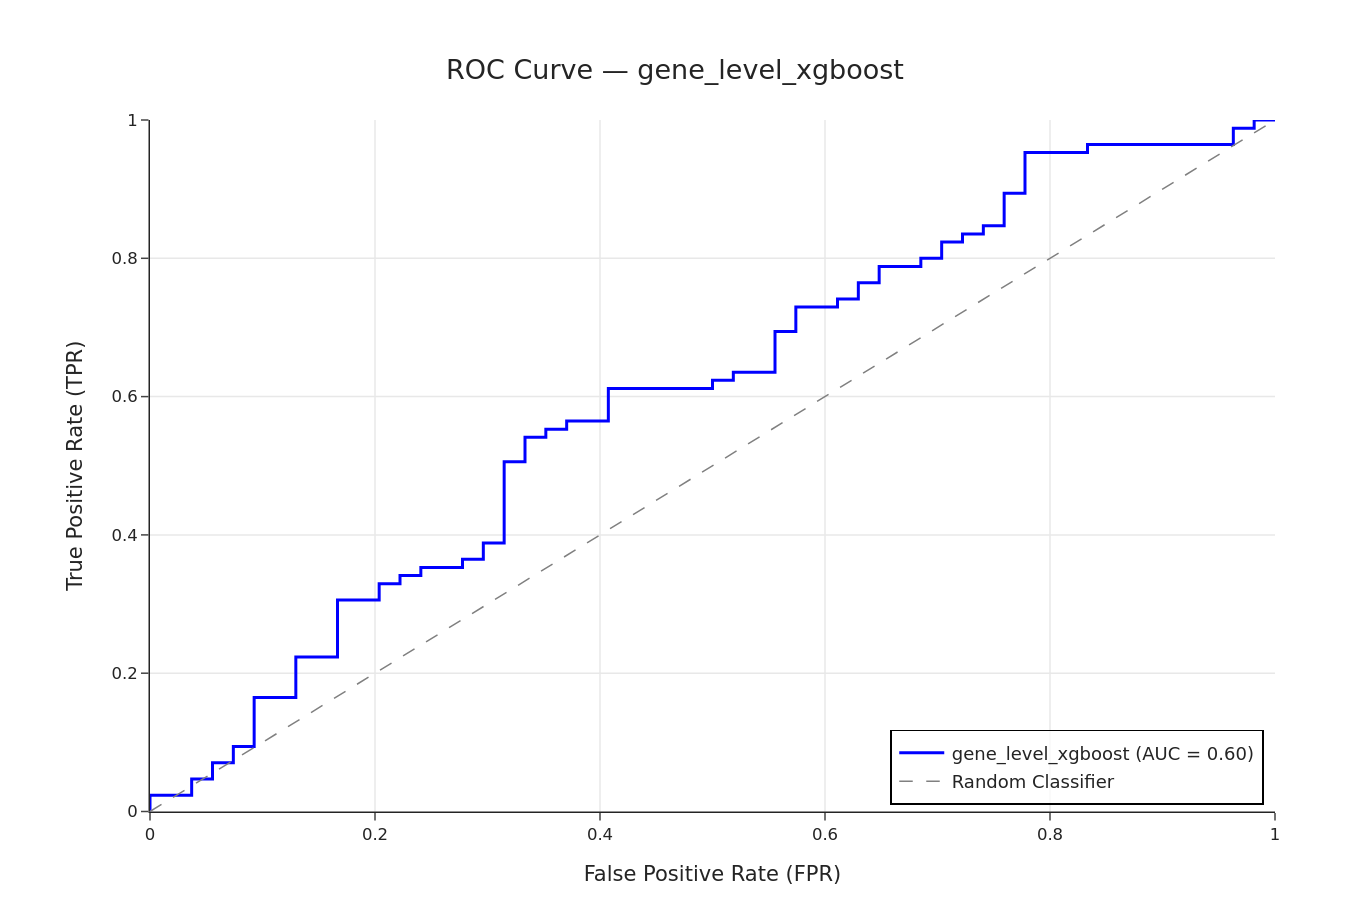

In [38]:
roc_curves_data = [
    {
        "y_true": (
            selected_predictions_df["y_true"].values
        ),
        "y_prob": (
            selected_predictions_df["y_prob_poly"].values
        ),
        "label": selected_representation,
        "is_main_curve": True,
    }
]

plot_roc_curves(
    curves_data=roc_curves_data,
    title=(
        f"ROC Curve — "
        f"{selected_representation}"
    ),
    interactive=False,
)

### ROC curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

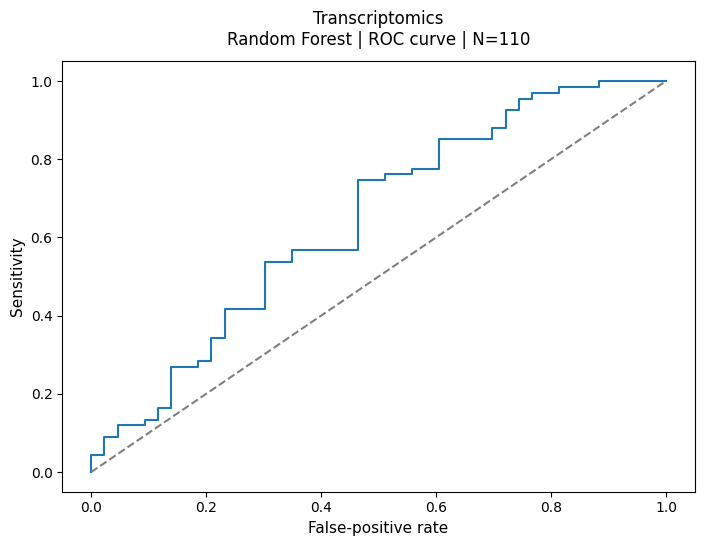

In [19]:
fig = plot_thesis_saved_figure('roc', 'transcriptomics')
plt.show()


### ROC Interpretation — Full availability (N=139)

Using pooled out-of-fold probabilities, the selected gene-level XGBoost model achieved a ROC-AUC of 0.6017. The mean outer-fold ROC-AUC was 0.6259. These estimates indicate only modest discrimination between oligometastatic and polymetastatic patients, with the model performing better than chance but without strong held-out separation.


### Precision–Recall curve — Full availability (N=139)

Because the oligometastatic and polymetastatic groups are imbalanced, precision-recall performance is examined alongside ROC-AUC using pooled out-of-fold predictions.

--- Plotting Precision–Recall Curve ---


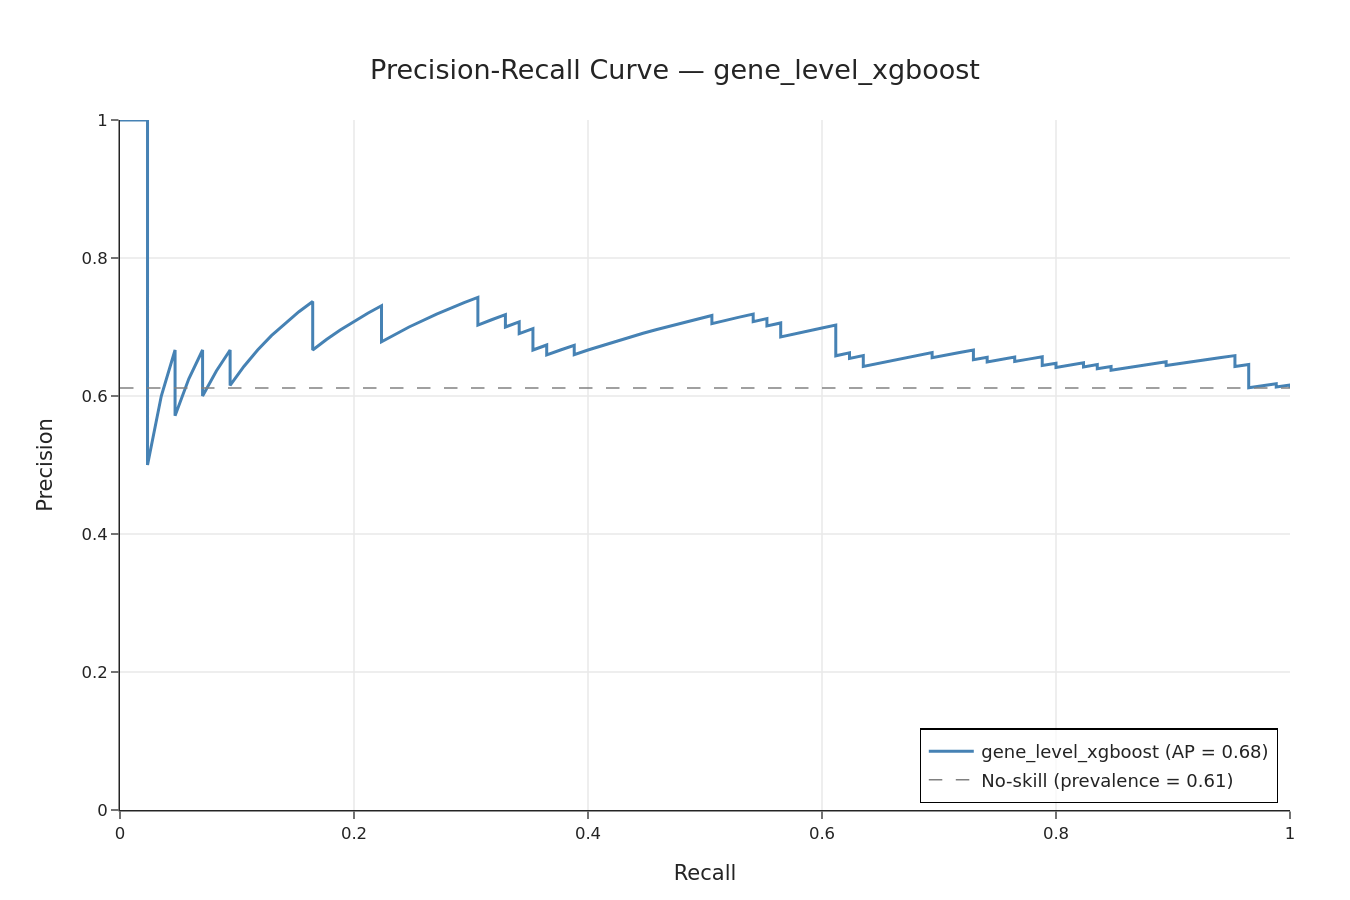

In [39]:
pr_curves_data = [
    {
        "y_true": (
            selected_predictions_df["y_true"].values
        ),
        "y_prob": (
            selected_predictions_df["y_prob_poly"].values
        ),
        "label": selected_representation,
        "is_main_curve": True,
    }
]

plot_precision_recall_curves(
    curves_data=pr_curves_data,
    title=(
        f"Precision-Recall Curve — "
        f"{selected_representation}"
    ),
    interactive=False,
)

### Precision–Recall curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

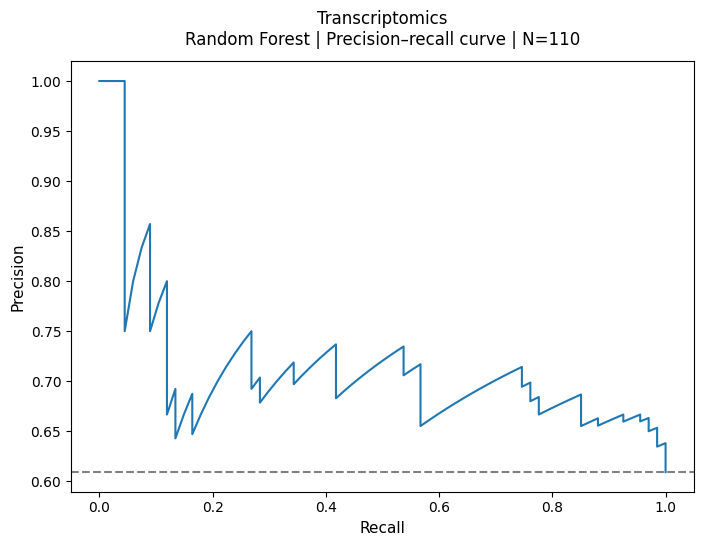

In [20]:
fig = plot_thesis_saved_figure('pr', 'transcriptomics')
plt.show()


### Precision-Recall Interpretation — Full availability (N=139)

The pooled average precision was 0.6841. Since the polymetastatic prevalence in the cohort was approximately 0.61, this is above the prevalence-based baseline but still only a modest improvement. Together with the ROC results, the precision-recall analysis suggests a weak-to-moderate predictive signal rather than strong class separation.


### Confusion matrix — Full availability (N=139)

The pooled out-of-fold confusion matrix shows the classification errors produced across all held-out outer folds at the classifier's default decision threshold.

--- Plotting Confusion Matrix ---


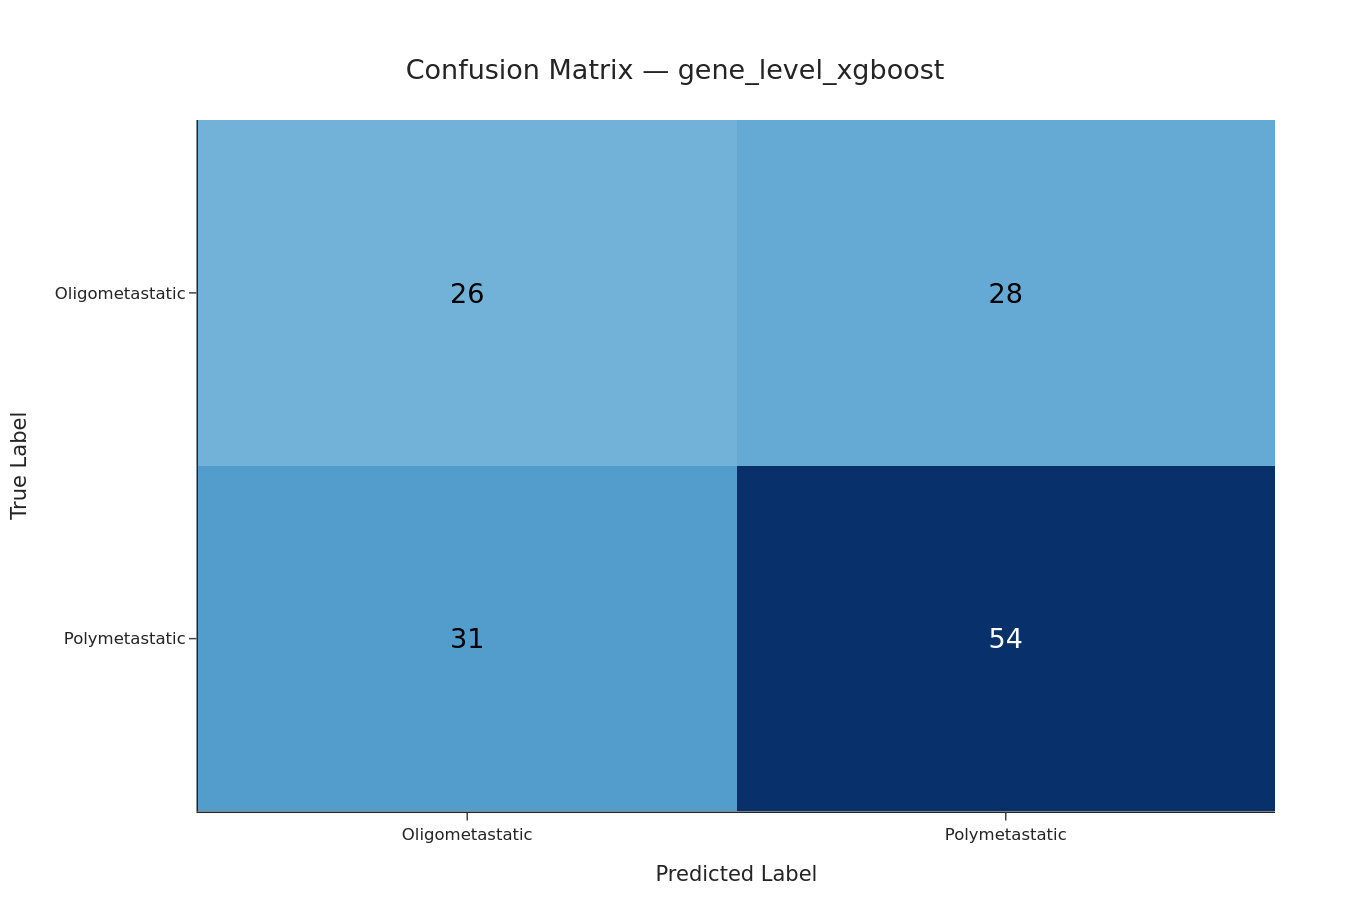

In [40]:
plot_confusion_matrix(
    y_true=selected_predictions_df["y_true"],
    y_pred=selected_predictions_df["y_pred"],
    class_labels=[
        "Oligometastatic",
        "Polymetastatic",
    ],
    title=(
        f"Confusion Matrix — "
        f"{selected_representation}"
    ),
    interactive=False,
)

### Confusion matrix — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

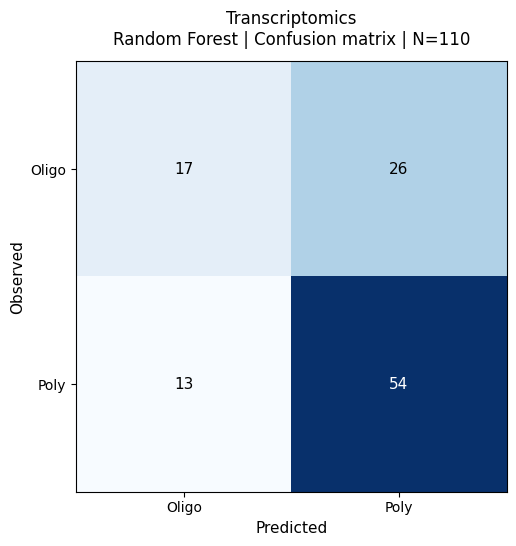

In [21]:
fig = plot_thesis_saved_figure('confusion_matrix', 'transcriptomics')
plt.show()


### Confusion Matrix Interpretation — Full availability (N=139)

The pooled out-of-fold confusion matrix corresponded to pooled sensitivity (recall for polymetastatic disease) of 0.6353 and pooled specificity (recall for oligometastatic disease) of 0.4815, with pooled balanced accuracy of 0.5584 and pooled macro-F1 of 0.5576. The model identified polymetastatic patients more often than oligometastatic patients, many of whom were misclassified.


### Calibration curve — Full availability (N=139)

Calibration is assessed using the pooled out-of-fold predicted probabilities. The calibration curve compares predicted polymetastatic probabilities with the observed fraction of polymetastatic patients, while the Brier score summarises probabilistic prediction error.

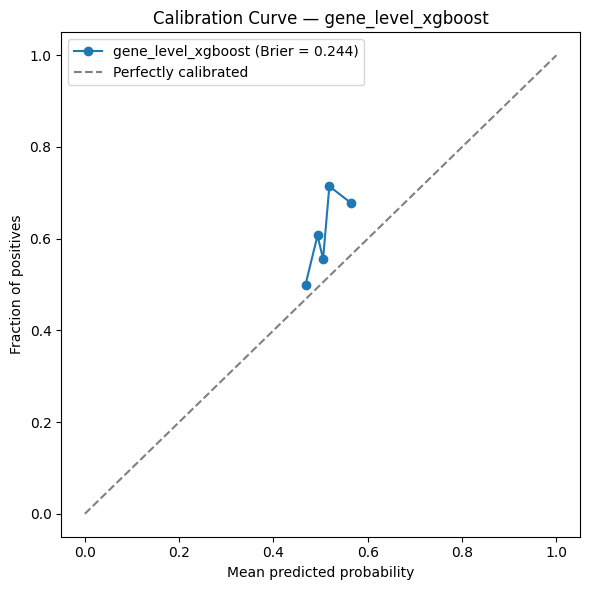

Brier score — gene_level_xgboost: 0.244


In [41]:
selected_calibration_df = (
    selected_predictions_df
    .rename(
        columns={
            "representation": "model",
            "y_prob_poly": "y_proba",
        }
    )
)

brier_score = plot_calibration_curve(
    predictions_df=selected_calibration_df,
    model_name=selected_representation,
    n_bins=5,
)

thesis_print(
    f"Brier score — "
    f"{selected_representation}: "
    f"{brier_score:.3f}"
)

### Calibration curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

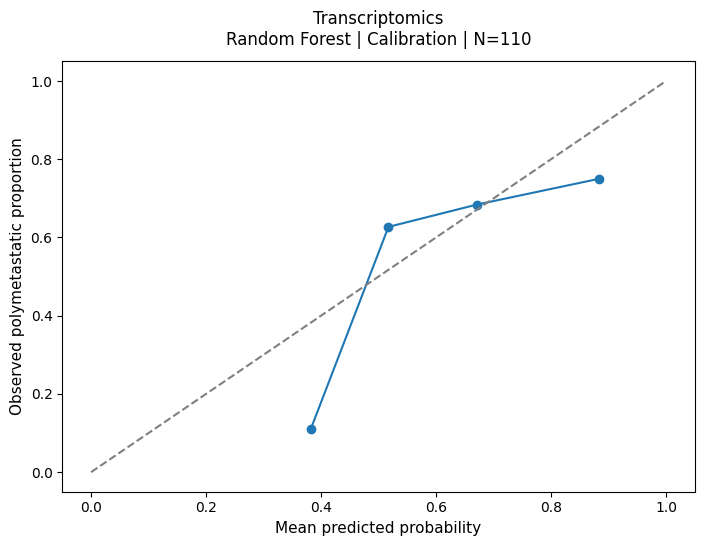

In [22]:
fig = plot_thesis_saved_figure('calibration', 'transcriptomics')
plt.show()


### Probability Calibration — Full availability (N=139)

The pooled out-of-fold Brier score for the selected gene-level XGBoost model was 0.2436. This summarises probability error and does not on its own show good calibration. Discrimination was modest, and the predicted probabilities should not be read as well-calibrated estimates of individual risk.


In [42]:
selected_results_df = (
    all_representation_results_df[
        all_representation_results_df[
            "representation"
        ] == selected_representation
    ]
    .copy()
)

mean_train_auc = (
    selected_results_df[
        "train_roc_auc"
    ].mean()
)

mean_test_auc = (
    selected_results_df[
        "test_roc_auc"
    ].mean()
)

train_test_auc_gap = (
    mean_train_auc
    - mean_test_auc
)

thesis_print(
    f"Mean train ROC-AUC: "
    f"{mean_train_auc:.3f}"
)

thesis_print(
    f"Mean test ROC-AUC: "
    f"{mean_test_auc:.3f}"
)

thesis_print(
    f"Train-test ROC-AUC gap: "
    f"{train_test_auc_gap:.3f}"
)

Mean train ROC-AUC: 0.994
Mean test ROC-AUC: 0.626
Train-test ROC-AUC gap: 0.368


### Generalisation Gap — Full availability (N=139)

The selected gene-level XGBoost model achieved a mean outer-train ROC-AUC of 0.9942 and a mean outer-test ROC-AUC of 0.6259, corresponding to a train-test ROC-AUC gap of 0.3683. This substantial gap indicates considerable overfitting: the model fit the training data very closely, but much of the apparent discrimination did not transfer to held-out patients.

The train-test gap is a diagnostic only and was not part of the model-selection criterion. The model was selected exclusively according to mean inner-CV macro-F1 across outer folds, while outer-fold performance was reserved for unbiased estimation.


## 5. Cross-representation performance diagnostics

The table above is easier to scan visually as a boxplot, showing the spread of outer-fold test performance for the top representation-classifier combinations. Each box summarises the five outer-fold values for one combination. Greater vertical spread indicates greater variability in performance across folds and therefore less stable generalisation estimates.

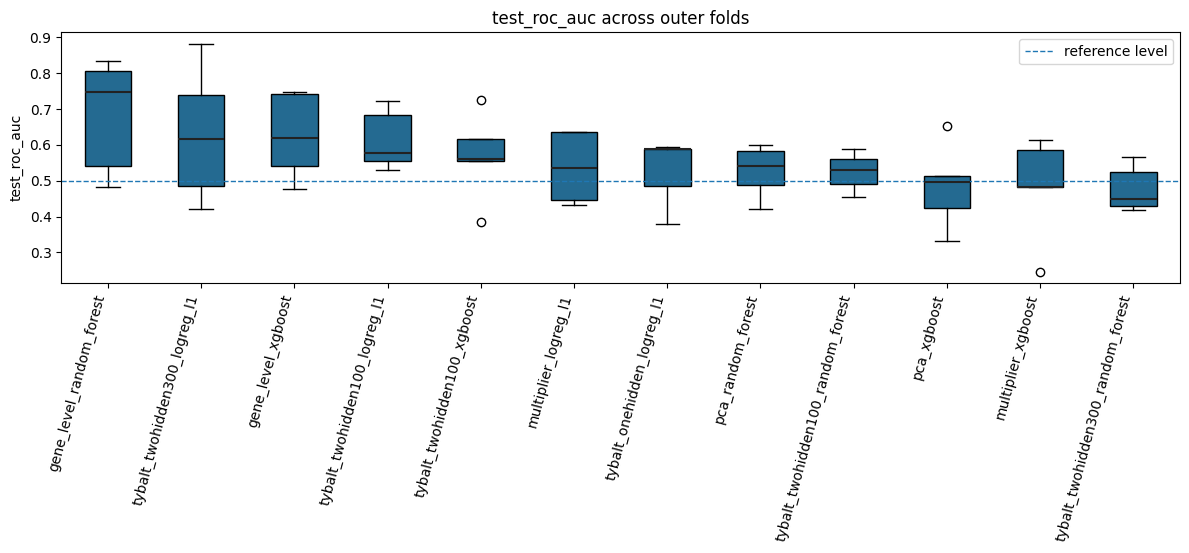

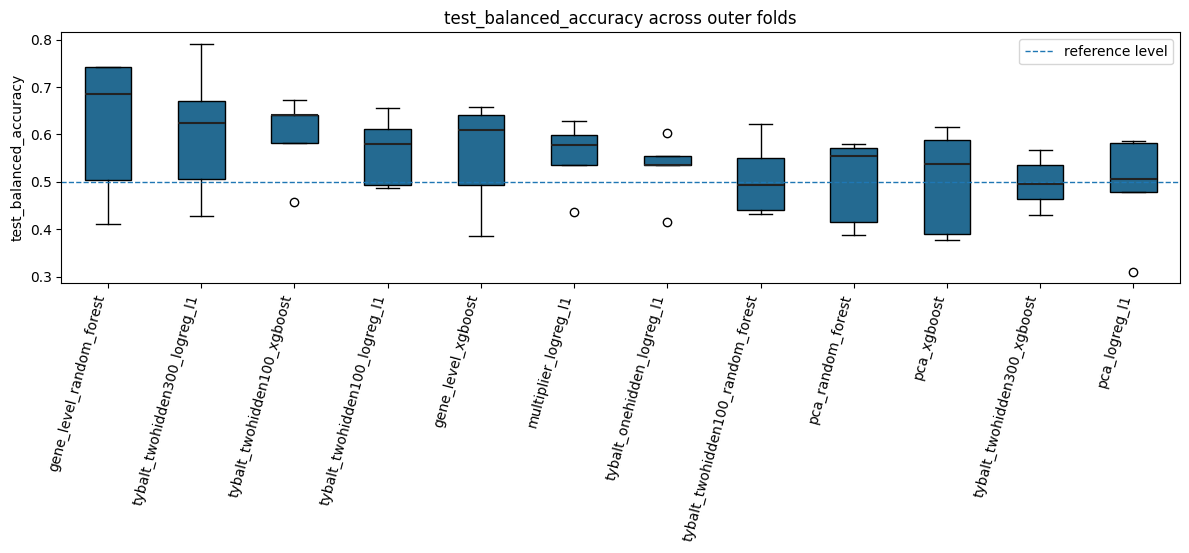

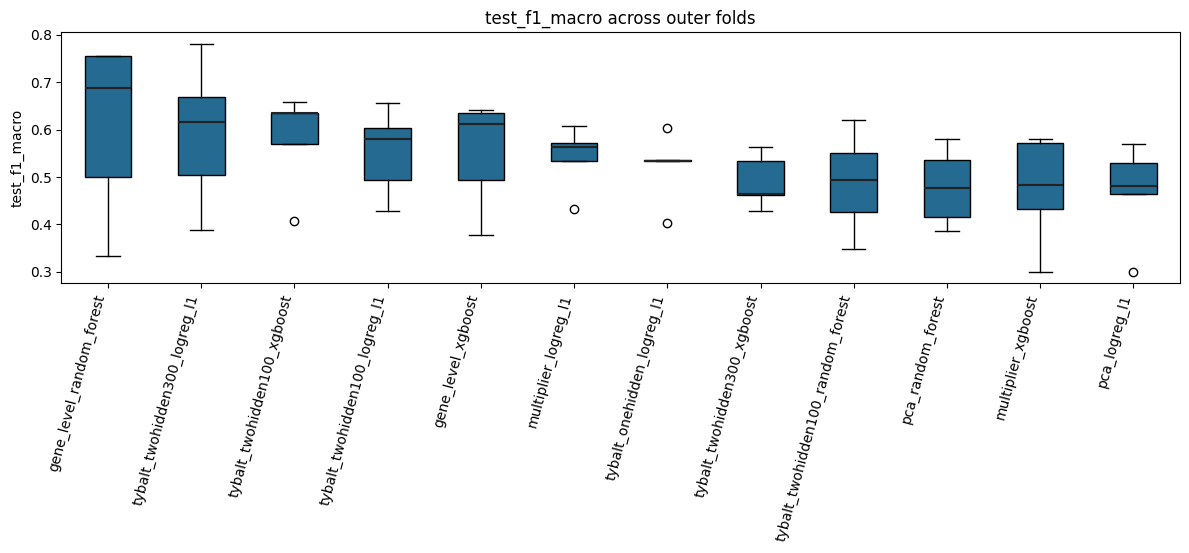

In [45]:
plot_metric_boxplots(
    all_results_df=all_representation_results_df,
    metric="test_roc_auc",
    top_n=12,
    chance_level=0.5,
)

plot_metric_boxplots(
    all_results_df=all_representation_results_df,
    metric="test_balanced_accuracy",
    top_n=12,
    chance_level=0.5,
)

plot_metric_boxplots(
    all_results_df=all_representation_results_df,
    metric="test_f1_macro",
    top_n=12,
    chance_level=None,
)

### Train–test diagnostics by context

The first table compares the selected family in each context. Train and outer-test AUC are means across five outer folds; the gap is their difference. The all-family common-cohort table is a secondary diagnostic, not a selection criterion.

In [6]:
p110_diagnostics = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_train_test.csv')
p110_primary_diag = p110_diagnostics.set_index('family').loc[p110_primary_family]
if p110_config == 'transcriptomics':
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / 'transcriptomics_representation_model_selection_summary_reviewed.csv').set_index('representation').loc[p110_secondary_family]
    p110_secondary_train = p110_secondary_diag['mean_train_roc_auc']
    p110_secondary_test = p110_secondary_diag['mean_test_roc_auc']
    p110_secondary_gap = p110_secondary_diag['train_test_gap']
else:
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / f'{p110_prefix}_train_test_comparison_reviewed.csv').set_index('model').loc[p110_secondary_family]
    p110_auc_key = 'auc_score' if p110_config == 'clinical' else 'roc_auc'
    p110_secondary_train = p110_secondary_diag[p110_auc_key + '_train']
    p110_secondary_test = p110_secondary_diag[p110_auc_key + '_test']
    p110_secondary_gap = p110_secondary_train - p110_secondary_test
thesis_display(p110_pd.DataFrame([
    {'Context':p110_secondary_label, 'Selected family':p110_secondary_family, 'Mean train AUC':p110_secondary_train,
     'Mean outer-test AUC':p110_secondary_test,'Train–test AUC gap':p110_secondary_gap},
    {'Context':p110_primary_label, 'Selected family':p110_primary_family, 'Mean train AUC':p110_primary_diag.roc_auc_train_mean,
     'Mean outer-test AUC':p110_primary_diag.roc_auc_test_mean,'Train–test AUC gap':p110_primary_diag.roc_auc_gap_mean},
]))
thesis_display(P110Markdown('**All common-cohort candidate families — diagnostic**'))
thesis_display(p110_diagnostics[['family','roc_auc_train_mean','roc_auc_train_std','roc_auc_test_mean','roc_auc_test_std','roc_auc_gap_mean','roc_auc_gap_std']].assign(Context=p110_primary_label))


,Context,Selected family,Mean train AUC,Mean outer-test AUC,Train–test AUC gap
0,Full availability (N=139),gene_level_xgboost,0.994,0.626,0.368
1,Common cohort (N=110),random_forest,0.991,0.649,0.342


**All common-cohort candidate families — diagnostic**

,family,roc_auc_train_mean,roc_auc_train_std,roc_auc_test_mean,roc_auc_test_std,roc_auc_gap_mean,roc_auc_gap_std,Context
0,logreg_l1,1.000,0.000,0.585,0.119,0.415,0.119,Common cohort (N=110)
1,random_forest,0.991,0.013,0.649,0.133,0.342,0.124,Common cohort (N=110)
2,xgboost,0.972,0.022,0.654,0.083,0.318,0.076,Common cohort (N=110)


### Apparent-training versus held-out performance gaps — Full availability (N=139)

The boxplots below show the difference between train and test performance for each representation-classifier combination, complementing the outer-fold test metrics above with a direct view of overfitting.

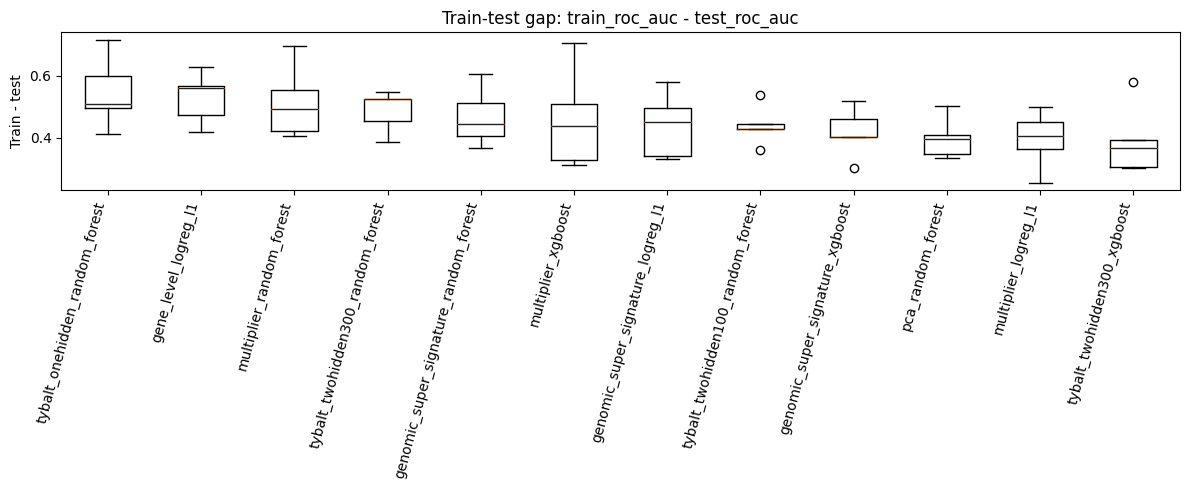

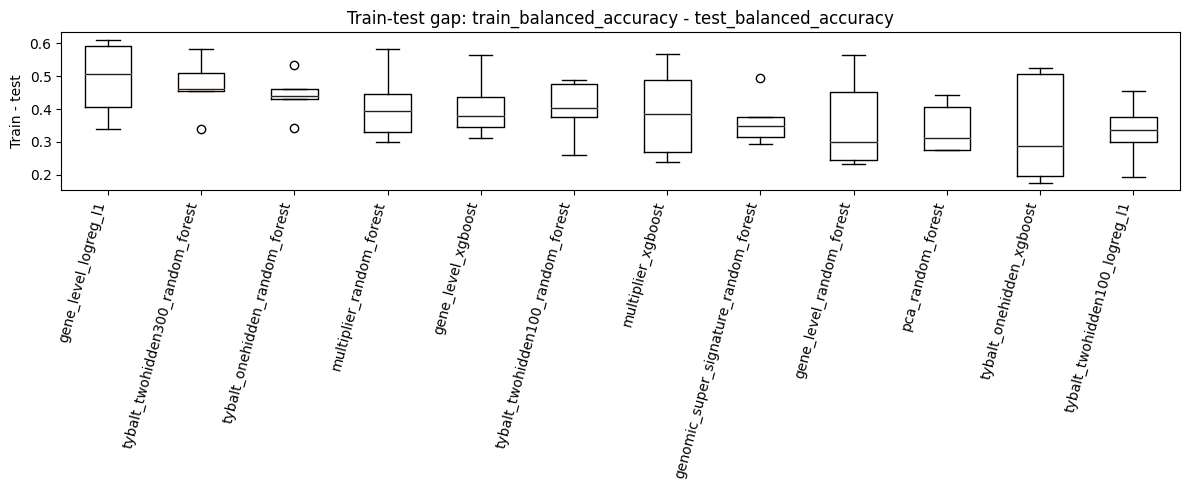

Apparent outer-training minus held-out outer-test performance; an overfitting diagnostic, not an inner-validation score.

In [46]:
plot_train_test_gap_boxplots(
    all_representation_results_df,
    train_col="train_roc_auc",
    test_col="test_roc_auc",
    top_n=12
)

plot_train_test_gap_boxplots(
    all_representation_results_df,
    train_col="train_balanced_accuracy",
    test_col="test_balanced_accuracy",
    top_n=12
)
display(Markdown('Apparent outer-training minus held-out outer-test performance; an overfitting diagnostic, not an inner-validation score.'))


### Summary of the predictive comparison

### Full availability (N=139)

Gene-level XGBoost was selected by the predefined inner-CV macro-F1 criterion. The selected model achieved a mean inner-CV macro-F1 of 0.6964 ± 0.0320 and ranked first in all 5/5 outer folds. The alternative gene-level Random Forest achieved a mean inner-CV macro-F1 of 0.6474 and a higher outer-test ROC-AUC (mean approximately 0.683; pooled approximately 0.686), but this was not used for model selection because outer-fold performance was reserved for unbiased estimation only.

The selected gene-level XGBoost model showed only modest held-out discrimination. Its mean outer-fold ROC-AUC was 0.6259, the pooled OOF ROC-AUC was 0.6017, pooled balanced accuracy was 0.5584, pooled macro-F1 was 0.5576, pooled average precision was 0.6841, and pooled OOF Brier score was 0.2436. Sensitivity (recall for polymetastatic disease) was 0.6353 and specificity (recall for oligometastatic disease) was 0.4815. These values indicate limited generalisation but some predictive signal.

Substantial overfitting was evident: the mean outer-train ROC-AUC was 0.9942 and the train-test ROC-AUC gap was 0.3683. This large gap indicates that the model fit the training data very closely but did not transfer as strongly to held-out patients.

No learned latent representation demonstrated a clear improvement over the raw gene-level representation under the predefined selection framework. The selected gene-level XGBoost model captured some signal, but predictive utility remained modest and the generalisation gap was substantial.


### Common cohort (N=110)

Gene-level Random Forest was selected by the highest mean inner-CV macro-F1 (0.653). Pooled OOF ROC-AUC was 0.642, balanced accuracy 0.601, macro-F1 0.600 and Brier score 0.225. This is the common-cohort result for cross-modality comparison on the same 110 patients and frozen outer folds. Performance remains exploratory and does not establish clinical utility.

### Interpretation

The common-cohort transcriptomics Random Forest is interpreted in the [common-cohort interpretation notebook](20260924-common-cohort-model-interpretation-oligopoly.ipynb).

Differences between contexts involve preprocessing and search spaces as well as cohort membership; they cannot be attributed solely to sample size. The N=139 representation benchmark, including latent representations, remains a secondary analysis. Only gene-level transcriptomics was evaluated as the common-cohort N=110 modality comparator.

> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis.

## 6. Supplementary FLAML benchmark

FLAML was run as a separate comparator on the same gene-level TPM matrix with the same frozen outer patients, five stratified inner folds, macro-F1 objective and seed 42. The aligned pooled OOF results were ROC-AUC 0.4495, balanced accuracy 0.5044, macro-F1 0.4783, average precision 0.5565, Brier score 0.2562, sensitivity (recall for polymetastatic disease) approximately 0.824, and specificity (recall for oligometastatic disease) approximately 0.185.

These results did not outperform the manually selected pipeline. FLAML displayed a strong sensitivity bias at the expense of very poor specificity, and it should be interpreted as a comparator rather than as a replacement for the predefined manual nested-CV selection protocol.

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments. 


In [47]:
with quiet_candidate_f_tests():
    flaml_test_path = Path(output_dir) / "transcriptomics_flaml_nested_test_aligned.csv"
    flaml_train_path = Path(output_dir) / "transcriptomics_flaml_nested_train_aligned.csv"
    flaml_oof_path = Path(output_dir) / "transcriptomics_flaml_oof_predictions_aligned.csv"
    flaml_test_df = flaml_train_df = flaml_oof_df = None
    if RUN_FLAML:
        flaml_test_df, flaml_train_df, flaml_oof_df = run_nested_cv_with_flaml_tpm(
            X, y, metadata_df, outer_splits, FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)
        flaml_test_df.to_csv(flaml_test_path, index=False)
        flaml_train_df.to_csv(flaml_train_path, index=False)
        flaml_oof_df.to_csv(flaml_oof_path, index=False)
    elif all(p.exists() for p in [flaml_test_path, flaml_train_path, flaml_oof_path]):
        flaml_test_df, flaml_train_df, flaml_oof_df = [pd.read_csv(p) for p in [flaml_test_path, flaml_train_path, flaml_oof_path]]
    elif any(p.exists() for p in [flaml_test_path, flaml_train_path, flaml_oof_path]):
        raise ValueError("Incomplete aligned FLAML bundle.")
    else:
        thesis_print("No aligned FLAML results saved; stage disabled.")
    if flaml_oof_df is not None:
        for frame in [flaml_test_df, flaml_train_df, flaml_oof_df]:
            if not frame.inner_n_splits.eq(5).all() or not frame.selection_metric.eq("macro_f1").all():
                raise ValueError("Saved FLAML protocol is not aligned.")
        for frame in [flaml_test_df, flaml_train_df]:
            if len(frame) != 5 or set(frame.outer_fold) != set(range(1, 6)):
                raise ValueError("Aligned FLAML requires one result per outer fold.")
        saved_budgets = pd.concat([flaml_test_df, flaml_train_df, flaml_oof_df]).time_budget_seconds.unique()
        if len(saved_budgets) != 1 or (FLAML_TIME_BUDGET_SECONDS is not None and saved_budgets[0] != FLAML_TIME_BUDGET_SECONDS):
            raise ValueError("Saved FLAML budget differs from the requested common budget.")
        flaml_oof_df = validate_tpm_oof(flaml_oof_df, "flaml_automl", metadata_df, y, outer_splits)
        flaml_pooled_df = pd.DataFrame([tpm_pooled_oof_metrics(flaml_oof_df)], index=["flaml_automl"])
        flaml_pooled_df.to_csv(Path(output_dir) / "transcriptomics_flaml_pooled_oof_metrics_aligned.csv")
        thesis_display(flaml_test_df, flaml_train_df, flaml_pooled_df)
        if manual_results_reviewed:
            manual_flaml_comparison_df = pd.concat([pooled_oof_df.loc[[selected_representation]], flaml_pooled_df])
            manual_flaml_comparison_df["mean_inner_cv_score"] = [representation_summary_df.loc[selected_representation, "mean_inner_cv_score"], flaml_test_df.best_inner_score.mean()]
            manual_flaml_comparison_df["mean_outer_roc_auc"] = [representation_summary_df.loc[selected_representation, "mean_test_roc_auc"], flaml_test_df.roc_auc.mean()]
            manual_flaml_comparison_df.to_csv(Path(output_dir) / "transcriptomics_manual_vs_flaml_aligned.csv")
            thesis_display(manual_flaml_comparison_df)

,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,flaml_automl,1,0.439,"{""best_estimator"": ""tpm_xgboost"", ""best_config...",macro_f1,5,120,test,0.332,0.471,0.364,0.593,0.941,0.000,0.513,0.259
1,flaml_automl,2,0.403,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,test,0.626,0.578,0.562,0.652,0.882,0.273,0.686,0.233
2,flaml_automl,3,0.530,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,test,0.380,0.444,0.427,0.571,0.706,0.182,0.540,0.277
3,flaml_automl,4,0.512,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,test,0.444,0.489,0.482,0.600,0.706,0.273,0.555,0.263
4,flaml_automl,5,0.613,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,test,0.471,0.541,0.518,0.652,0.882,0.200,0.614,0.249


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,flaml_automl,1,0.439,"{""best_estimator"": ""tpm_xgboost"", ""best_config...",macro_f1,5,120,train,0.965,0.686,0.688,0.716,1.000,0.372,0.973,0.179
1,flaml_automl,2,0.403,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,train,0.987,0.930,0.941,0.919,1.000,0.860,0.990,0.132
2,flaml_automl,3,0.530,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,train,0.960,0.930,0.941,0.919,1.000,0.860,0.950,0.134
3,flaml_automl,4,0.512,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,train,0.983,0.923,0.932,0.918,0.985,0.860,0.989,0.134
4,flaml_automl,5,0.613,"{""best_estimator"": ""tpm_random_forest"", ""best_...",macro_f1,5,120,train,0.996,0.977,0.981,0.971,1.000,0.955,0.997,0.127


,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
flaml_automl,0.449,0.504,0.478,0.614,0.824,0.185,0.557,0.256


,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
gene_level_xgboost,0.602,0.558,0.558,0.659,0.635,0.481,0.684,0.244,0.696,0.626
flaml_automl,0.449,0.504,0.478,0.614,0.824,0.185,0.557,0.256,0.499,0.450


## 7. Supplementary Tybalt gene attribution

This experiment attributes predictions from the Tybalt twohidden100 encoder–classifier chain back to input genes. **Gene-level XGBoost remains the globally selected predictive model.** No predictive benchmark result is replaced.

A fresh interpretation-only search used five stratified folds, shuffle/seed 42 and macro-F1, with the existing L1 grid: C = 0.001/0.01/0.1/1, class weight None/balanced, and passthrough/SMOTE sampling. Input min–max scaling and latent standardization remained inside the tuning pipeline. The best pipeline was refitted on all 139 patients; its tuning score is not an unbiased performance estimate.

The exact path is 5,000 ordered aligned gene-symbol inputs → fitted MinMaxScaler → clipping to [0,1] → frozen twohidden100 encoder (100 latent coordinates) → fitted StandardScaler → L1 logistic regression → P(polymetastatic = 1). Sampling acts during fitting only. Upstream alignment averages multiple expression features mapping to a gene symbol and fills 706 unavailable genes with zero; no new alignment or encoder training was performed.

The original Tybalt `process_data.ipynb` and `tybalt_twohidden.ipynb` document zero-to-one expression scaling but do not specify an IG baseline. Here the reference is the **zero vector after fitted min–max transformation**, corresponding to the fitted per-gene minima in aligned log-expression coordinates. It is neither healthy tissue nor biological zero and need not correspond to an observed patient. Both coordinate forms are saved in `baseline.csv`.

In [ ]:
# Display preserved interpretation results only; this cell never fits a model.
TYBALT_IG_BUNDLE = Path("/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/Tybalt/interpretation_only_twohidden100_l1/validated_20260913T220128Z_7226e5db")
tybalt_ig = load_tybalt_ig_results(TYBALT_IG_BUNDLE)
p = tybalt_ig['params']
thesis_display(pd.DataFrame([{'interpretation_only': True, 'representation': p['representation'],
    'scoring': p['scoring'], 'inner_folds': p['n_splits'],
    'interpretation_tuning_macro_f1': p['best_inner_cv_score'], **p['best_params']}]))
thesis_display(pd.DataFrame([{k: v for k, v in tybalt_ig['agreement'].items()
    if k not in ['classifier_coordinate_order', 'patient_order_sha256', 'gene_order_sha256']}]))

interpretation_only,representation,scoring,inner_folds,interpretation_tuning_macro_f1,classifier__C,classifier__class_weight,sampler,selector
True,tybalt_twohidden100_logreg_l1,f1_macro,5,0.615,1,None,passthrough,passthrough


max_probability_difference,max_ig_float32_probability_difference,max_latent_difference,input_dim,latent_dim,classes,target,baseline_probability
9.91e-8,8.40e-7,4.00e-6,5000,100,"[0, 1]",P(polymetastatic = 1),0.156


### Prediction agreement and integration accuracy

Patient/gene ordering, encoder dimensions, latent coordinate order and class coding were checked before IG. The maximum sklearn–TensorFlow probability difference was 9.91×10⁻⁸; using the float32 coordinates supplied to the integrator it was 8.40×10⁻⁷. The maximum latent difference was 3.81×10⁻⁶.

Trapezoidal integration at 64/128/256 steps was insufficient for the completeness criterion. Resolution was increased with the same saved model and baseline; no tuning was repeated. Publication required maximum absolute completeness residual ≤0.001 and both mean and maximum attribution changes ≤0.001. The accepted 4,096-step result has maximum residual 0.000787 and mean residual 0.000157. These checks assess numerical fidelity, not predictive validity.

In [ ]:
thesis_display(tybalt_ig['checks'])

steps,max_absolute_completeness_residual,mean_absolute_completeness_residual,mean_absolute_change,max_absolute_change
64,0.053,0.010,NaN,NaN
128,0.034,0.005,2.66e-5,9.23e-4
256,0.022,0.003,1.35e-5,4.58e-4
512,0.009,0.001,6.79e-6,1.95e-4
1024,0.004,6.06e-4,3.36e-6,9.80e-5
2048,0.002,2.80e-4,1.69e-6,4.70e-5
4096,7.87e-4,1.57e-4,8.36e-7,2.60e-5


### Gene-level IG ranking

Mean absolute IG ranks attribution magnitude across patients. Mean signed IG describes direction relative to the specified baseline: positive values contribute toward higher predicted polymetastatic probability, negative values toward lower probability. The complete signed and absolute 139×5,000 matrices and all gene ranks are preserved in the validated bundle. These are model-specific contributions, not independent gene associations or causal effects.

In [ ]:
thesis_display(tybalt_ig['ranking'].head(20))

gene_name,mean_absolute_ig,mean_signed_ig
ACBD7,0.042,0.042
SCGB3A2,0.041,0.041
DPY19L2,0.038,-0.038
CAMK2N1,0.036,-0.036
UGT1A7,0.033,0.033
NBEA,0.032,-0.032
GABRP,0.032,-0.032
SLC25A27,0.032,-0.032
UGT1A1,0.032,0.032
CD6,0.032,-0.032


ACBD7 and SCGB3A2 have the largest mean absolute attributions, with positive mean signs; DPY19L2 and CAMK2N1 follow with negative signs. These priorities describe how this frozen encoder and fitted L1 classifier use the aligned input relative to the model reference baseline. They do not establish metastatic mechanisms or validated biomarkers.

The analysis provides the proposed gene-level view through a differentiable encoder–classifier chain. It does not establish a predictive advantage for Tybalt, change the benchmark's model selection, or supply independent validation. Baseline choice, external-to-institutional transfer, upstream gene alignment and limited cohort size constrain interpretation. The twohidden300 experiment was not run.